# Week 4 Assignment: Time-Series, Proportions & Hierarchies

Course: Data Visualization
Name: Sajid Ali
Roll No: 078

All data is synthetic course data (CDB601220, Week 4).

Order of the notebook:
- Part A: nine broken charts
- Part D step 1: cleaning the sessions data (Part B needs it, so it comes first)
- Part B: windows and smoothing
- Part C: part-to-whole tests and the pie experiment
- Part D step 2: the 2x2 figure
- Part E: justification

In [12]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Force Python to prioritize the local folder /content over dist-packages
if '/content' in sys.path:
    sys.path.remove('/content')
sys.path.insert(0, '/content')

# Unload any previously cached global 'tslib' package to prevent import shadowing
if 'tslib' in sys.modules:
    del sys.modules['tslib']

import tslib
from tslib import PALETTE, save_fig

tslib.style_defaults()

DATA = ""
OUT = "outputs/"
os.makedirs(OUT, exist_ok=True)

blue, orange, green = PALETTE["series"]
pink = PALETTE["series_4th"]
grey = PALETTE["muted"]

---
# Part A: Rebuild nine charts, then take them apart

## Case 1: "Orders peak in Q1 and collapse every year"

Recipe: sort by `month`, line with markers, y from zero.

In [28]:
c1 = pd.read_csv(DATA + "case01_orders_stringdate.csv")
c1 = c1.sort_values("month")

print(c1["month"].tolist())
print("changes:", c1["orders"].diff().tolist())

['2024-1', '2024-10', '2024-11', '2024-12', '2024-2', '2024-3', '2024-4', '2024-5', '2024-6', '2024-7', '2024-8', '2024-9', '2025-1', '2025-10', '2025-11', '2025-12', '2025-2', '2025-3', '2025-4', '2025-5', '2025-6', '2025-7', '2025-8', '2025-9']
changes: [nan, 850.0, 115.0, 94.0, -958.0, 85.0, 85.0, 103.0, 86.0, 115.0, 119.0, 62.0, 394.0, 854.0, 78.0, 123.0, -978.0, 112.0, 108.0, 59.0, 112.0, 70.0, 106.0, 86.0]


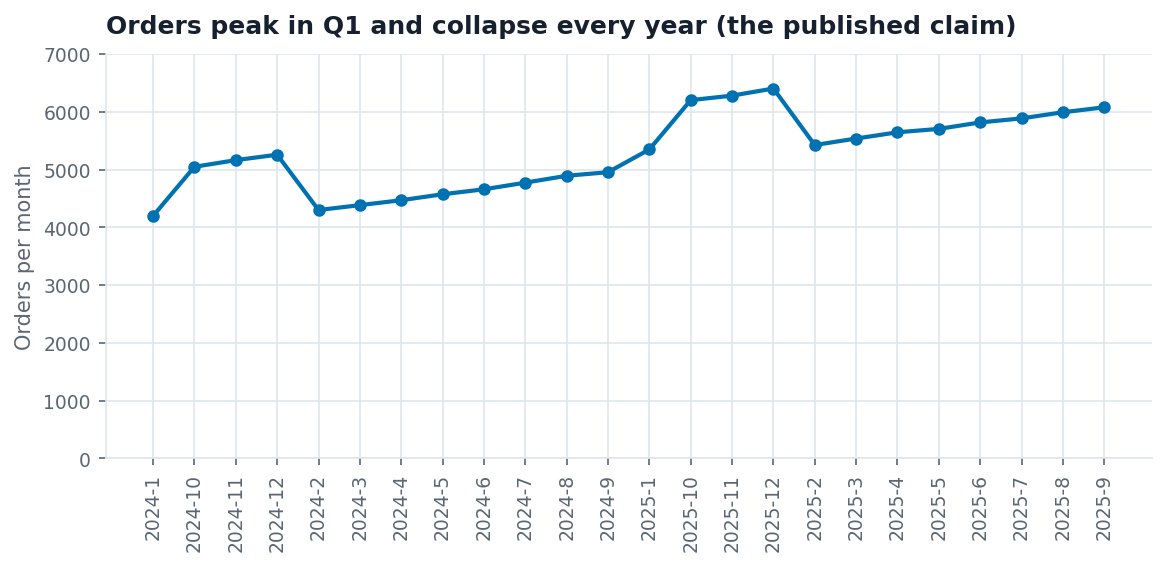

In [29]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(c1["month"], c1["orders"], marker="o", color=blue)
ax.set_ylim(0, 7000)
ax.set_title("Orders peak in Q1 and collapse every year (the published claim)")
ax.set_ylabel("Orders per month")
ax.tick_params(axis="x", rotation=90)
fig.savefig(OUT + "A1_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 24 points, drops of 958 and 978. Matches.

Now checking the `month` column.

In [30]:
print("dtype of month:", c1["month"].dtype)
print("unique months:", c1["month"].nunique())
print("branches:", c1["branch"].unique())

c1["date"] = pd.to_datetime(c1["month"], format="%Y-%m")
c1 = c1.sort_values("date")

print("smallest month-to-month change after a real date sort:", c1["orders"].diff().min())
print("Jan 2024:", c1["orders"].iloc[0], "   Dec 2025:", c1["orders"].iloc[-1])

wrong_place = (c1["date"].dt.month >= 10).sum()
print("rows moved by the text sort (months 10, 11, 12):", wrong_place)

dtype of month: object
unique months: 24
branches: ['Gulberg']
smallest month-to-month change after a real date sort: 59.0
Jan 2024: 4200    Dec 2025: 6405
rows moved by the text sort (months 10, 11, 12): 6


- Conclusion: orders rise each year and then crash, so there is a yearly cycle.
- Decoy: maybe two branches are mixed. No, there is only one branch (Gulberg) and 24 different months.
- Mechanism: `month` is text, so it sorts as letters. "2024-10" comes before "2024-2", so 6 rows (Oct, Nov, Dec) end up in the wrong place. The "drop of 958" is really Dec 2024 going back to Feb 2024.
- After parsing the dates, the smallest monthly change is +59. Orders went up every month, 4,200 to 6,405.

Redesign: parse the dates first, then plot.

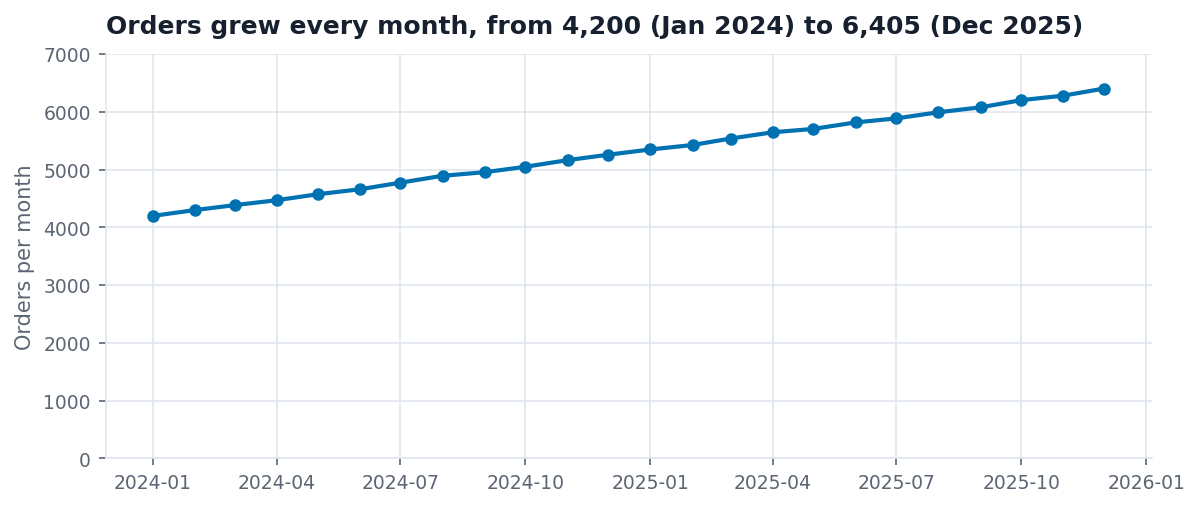

In [31]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(c1["date"], c1["orders"], marker="o", color=blue)
ax.set_ylim(0, 7000)
ax.set_title("Orders grew every month, from 4,200 (Jan 2024) to 6,405 (Dec 2025)")
ax.set_ylabel("Orders per month")
fig.savefig(OUT + "A1_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 2: "Sales grew steadily, 22%, across the quarter"

Recipe: plot sales against the row number and add a trend line.

In [32]:
c2 = pd.read_csv(DATA + "case02_shop_closed.csv")

x = np.arange(len(c2))
slope, intercept = np.polyfit(x, c2["sales_pkr_k"], 1)

first = c2["sales_pkr_k"].iloc[0]
last = c2["sales_pkr_k"].iloc[-1]
print("points:", len(c2), " first:", first, " last:", last, " change:", round((last / first - 1) * 100, 1), "%")

points: 69  first: 207  last: 253  change: 22.2 %


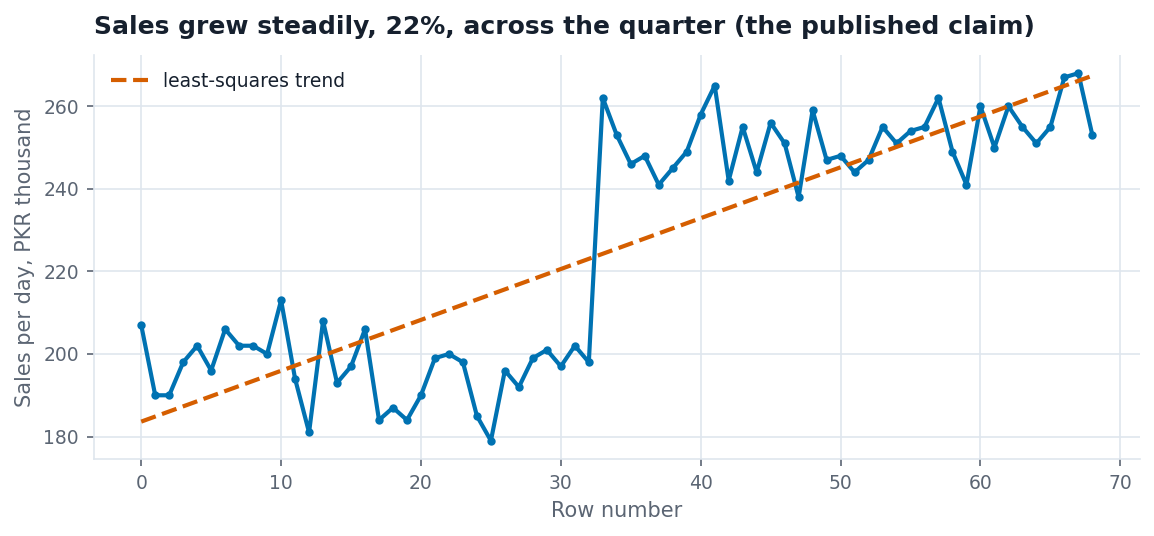

In [33]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(x, c2["sales_pkr_k"], marker="o", markersize=3, color=blue)
ax.plot(x, slope * x + intercept, color=orange, linestyle="--", label="least-squares trend")
ax.set_title("Sales grew steadily, 22%, across the quarter (the published claim)")
ax.set_xlabel("Row number")
ax.set_ylabel("Sales per day, PKR thousand")
ax.legend()
fig.savefig(OUT + "A2_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 69 points, 207 to 253, +22%. Matches.

Comparing the number of rows with the number of days.

In [34]:
c2["date"] = pd.to_datetime(c2["date"])
c2 = c2.set_index("date")

span = (c2.index.max() - c2.index.min()).days + 1
print("rows:", len(c2), "  days in the span:", span)

audit = tslib.audit_index(c2, "D")
print(audit)

rows: 69   days in the span: 90
{'dtype_ok': True, 'monotonic': True, 'n_rows': 69, 'n_duplicated': 0, 'n_missing': 21, 'missing_dates': ['2025-02-03 00:00:00', '2025-02-04 00:00:00', '2025-02-05 00:00:00', '2025-02-06 00:00:00', '2025-02-07 00:00:00', '2025-02-08 00:00:00', '2025-02-09 00:00:00', '2025-02-10 00:00:00', '2025-02-11 00:00:00', '2025-02-12 00:00:00', '2025-02-13 00:00:00', '2025-02-14 00:00:00'], 'span': ('2025-01-01 00:00:00', '2025-03-31 00:00:00'), 'partial_tail': False, 'tail_period': '2025-03', 'tail_count': 31}


In [35]:
print("mean sales by weekday:")
print(c2.groupby(c2.index.day_name())["sales_pkr_k"].mean().round(1))

before = c2.loc[:"2025-02-02", "sales_pkr_k"]
after = c2.loc["2025-02-24":, "sales_pkr_k"]
print("before the gap: mean", round(before.mean(), 1), " slope per day", round(np.polyfit(np.arange(len(before)), before, 1)[0], 2))
print("after the gap:  mean", round(after.mean(), 1), " slope per day", round(np.polyfit(np.arange(len(after)), after, 1)[0], 2))
print("step:", round((after.mean() / before.mean() - 1) * 100, 1), "%")

mean sales by weekday:
date
Friday       222.4
Monday       226.9
Saturday     223.8
Sunday       224.3
Thursday     225.4
Tuesday      231.9
Wednesday    224.5
Name: sales_pkr_k, dtype: float64
before the gap: mean 196.2  slope per day -0.16
after the gap:  mean 252.3  slope per day 0.23
step: 28.6 %


- Conclusion: sales grew a little every day.
- Decoy: maybe weekends are missing. No, the 21 missing days are 3 of each weekday, and weekday means are all 222 to 232.
- Mechanism: the span is 90 days but there are only 69 rows. The shop was closed 3 to 23 Feb (21 days), and the row number axis hides that.
- Inside each part sales are flat (about 196 before, 252 after). It is one step of +28.6%, not steady growth.

Redesign: put the missing days back so the line breaks, and show the two levels.

missing days now shown as gaps: 21


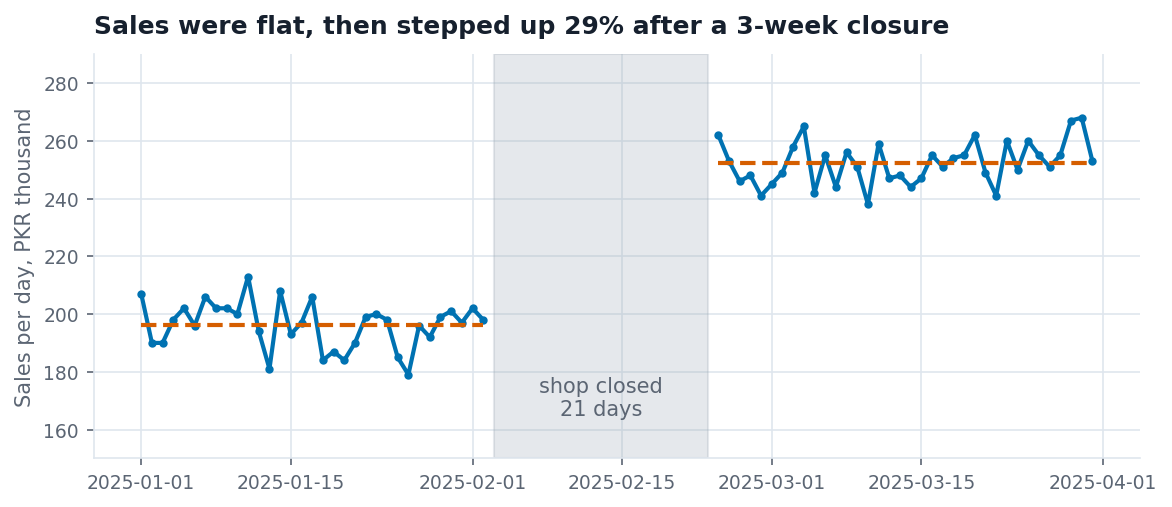

In [36]:
full = tslib.reindex_full(c2["sales_pkr_k"], "D")
print("missing days now shown as gaps:", full.isna().sum())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(full.index, full.values, marker="o", markersize=3, color=blue)
ax.axvspan(pd.Timestamp("2025-02-03"), pd.Timestamp("2025-02-23"), color=grey, alpha=0.25)
ax.text(pd.Timestamp("2025-02-13"), 165, "shop closed\n21 days", ha="center", color=PALETTE["ink_soft"])
ax.hlines(before.mean(), before.index.min(), before.index.max(), color=orange, linestyle="--")
ax.hlines(after.mean(), after.index.min(), after.index.max(), color=orange, linestyle="--")
ax.set_ylim(150, 290)
ax.set_title("Sales were flat, then stepped up 29% after a 3-week closure")
ax.set_ylabel("Sales per day, PKR thousand")
fig.savefig(OUT + "A2_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

This is a line chart, so the y-axis does not have to start at zero. Dashed lines are the mean of each part.

## Case 3: "Peak load jumped 43% overnight on 1 July"

Recipe: resample `concurrent_users` to daily with `.sum()`, line from zero.

In [37]:
c3 = pd.read_csv(DATA + "case03_bandwidth_levels.csv")
c3["ts"] = pd.to_datetime(c3["ts"])
c3 = c3.set_index("ts")

daily_sum = c3["concurrent_users"].resample("D").sum()
june = daily_sum["2025-06"].mean()
july = daily_sum["2025-07"].mean()
print("June daily mean:", round(june), " July daily mean:", round(july), " change:", round((july / june - 1) * 100, 1), "%")

June daily mean: 8782  July daily mean: 12543  change: 42.8 %


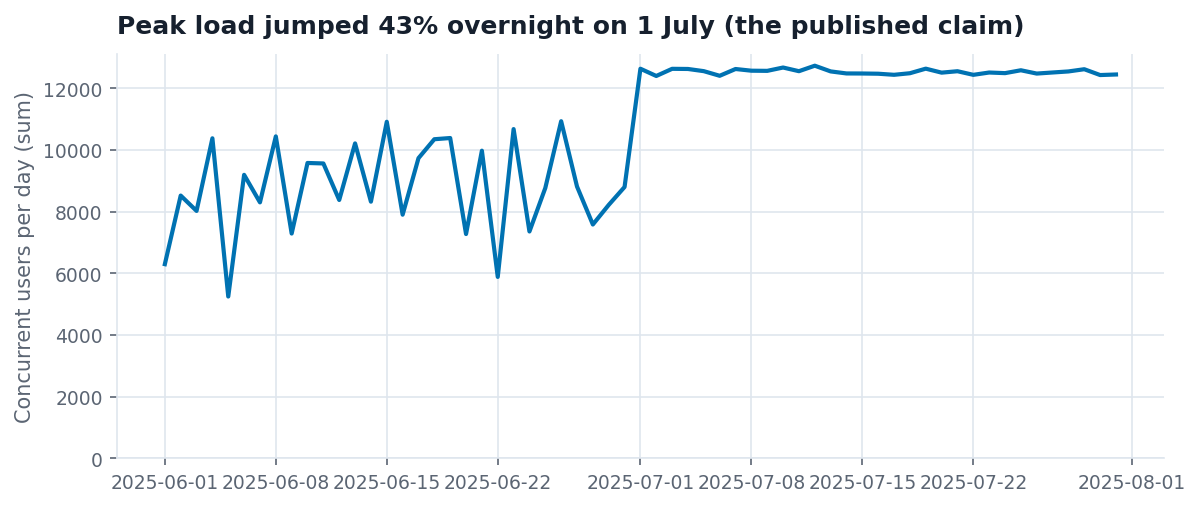

In [38]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(daily_sum.index, daily_sum.values, color=blue)
ax.set_ylim(0, None)
ax.set_title("Peak load jumped 43% overnight on 1 July (the published claim)")
ax.set_ylabel("Concurrent users per day (sum)")
fig.savefig(OUT + "A3_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: June about 8,800, July about 12,500, +43%. Matches.

In [39]:
print(tslib.audit_index(c3, "h"))

hours = c3["concurrent_users"].resample("D").count()
print("hours recorded per day — June mean:", round(hours["2025-06"].mean(), 1), " July mean:", round(hours["2025-07"].mean(), 1))

daily_mean = c3["concurrent_users"].resample("D").mean()
daily_peak = c3["concurrent_users"].resample("D").max()
print("mean users per hour — June:", round(daily_mean["2025-06"].mean()), " July:", round(daily_mean["2025-07"].mean()))
print("daily peak users   — June:", round(daily_peak["2025-06"].mean()), " July:", round(daily_peak["2025-07"].mean()))

{'dtype_ok': True, 'monotonic': True, 'n_rows': 1237, 'n_duplicated': 0, 'n_missing': 227, 'missing_dates': ['2025-06-01 12:00:00', '2025-06-01 13:00:00', '2025-06-01 14:00:00', '2025-06-01 15:00:00', '2025-06-01 16:00:00', '2025-06-01 17:00:00', '2025-06-01 18:00:00', '2025-06-01 19:00:00', '2025-06-01 20:00:00', '2025-06-01 21:00:00', '2025-06-02 13:00:00', '2025-06-02 14:00:00'], 'span': ('2025-06-01 00:00:00', '2025-07-31 23:00:00'), 'partial_tail': False, 'tail_period': '2025-07-31', 'tail_count': 24}
hours recorded per day — June mean: 16.4  July mean: 24.0
mean users per hour — June: 536  July: 523
daily peak users   — June: 779  July: 808


- Conclusion: something on 1 July made server load jump by 43%.
- Decoy: "a sum is just total users". No, `concurrent_users` is a level (users online at that moment), so adding snapshots does not count anything real.
- Mechanism: a level summed per day depends on how many hours were recorded. 227 hours are missing, all in June. June days have 16.4 hours on average, July days have 24, and 24 / 16.4 is about 1.46.
- Real load barely changed: mean users per hour 536 to 523, daily peak 779 to 808 (+3.7%).

Redesign: use `max()` for peak load, with the hours recorded per day shown below it.

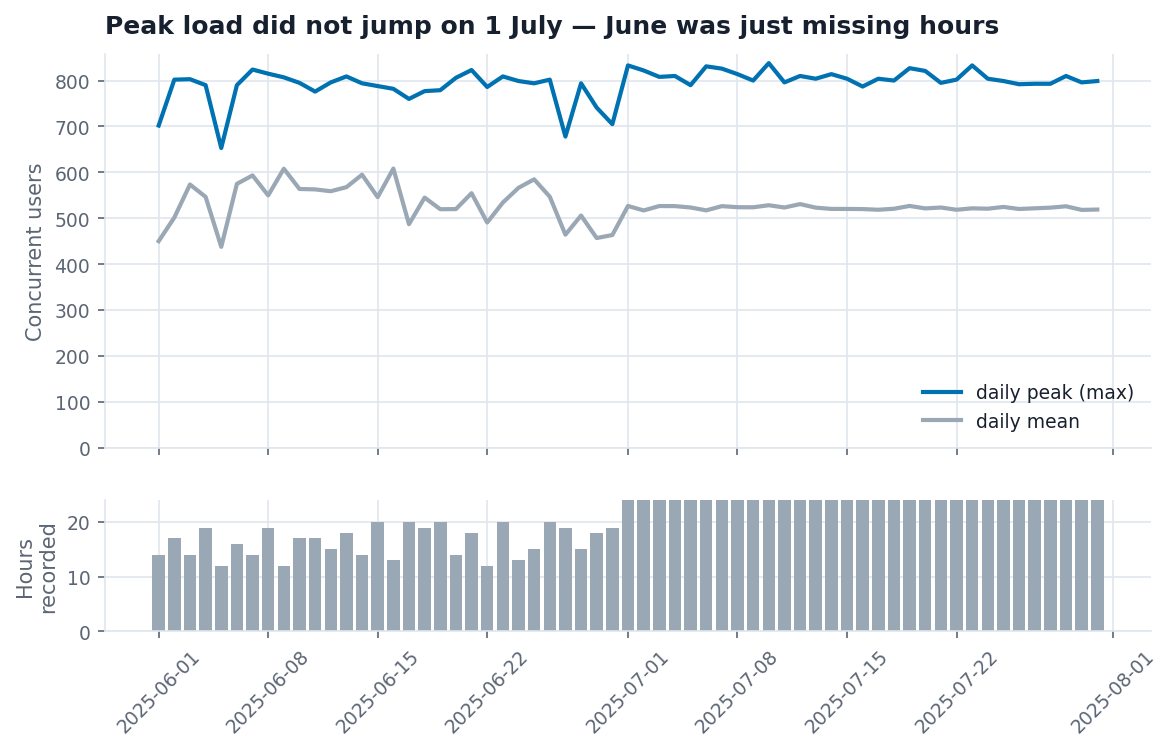

In [40]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(daily_peak.index, daily_peak.values, color=blue, label="daily peak (max)")
ax1.plot(daily_mean.index, daily_mean.values, color=grey, label="daily mean")
ax1.set_ylim(0, None)
ax1.set_ylabel("Concurrent users")
ax1.set_title("Peak load did not jump on 1 July — June was just missing hours")
ax1.legend(loc="lower right")

ax2.bar(hours.index, hours.values, color=grey)
ax2.set_ylim(0, 24)
ax2.set_ylabel("Hours\nrecorded")
ax2.tick_params(axis="x", rotation=45)

fig.savefig(OUT + "A3_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 4: "The new checkout flow started working on 7 September"

Recipe: raw in grey, 31-day trailing mean on top, mark where it turns.

In [41]:
c4 = pd.read_csv(DATA + "case04_intervention_lag.csv")
c4["date"] = pd.to_datetime(c4["date"])
c4 = c4.set_index("date")["conversion_pct"]

trailing = c4.rolling(31).mean()
turn = trailing.idxmin()
print("trailing mean bottoms out on:", turn.date())

trailing mean bottoms out on: 2025-09-07


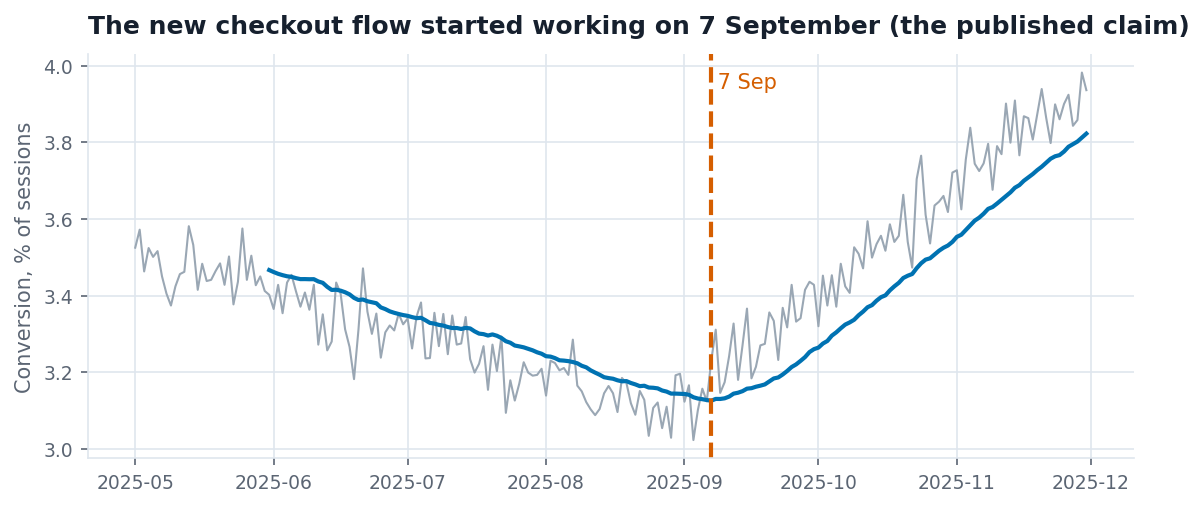

In [42]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(c4.index, c4.values, color=grey, linewidth=1)
ax.plot(trailing.index, trailing.values, color=blue)
ax.axvline(turn, color=orange, linestyle="--")
ax.text(turn, c4.max(), " 7 Sep", color=orange, va="top")
ax.set_title("The new checkout flow started working on 7 September (the published claim)")
ax.set_ylabel("Conversion, % of sessions")
fig.savefig(OUT + "A4_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: the trailing mean bottoms out on 2025-09-07. Matches.

In [43]:
lag = tslib.lag_at_turn(c4, 31, how="min")
print(lag)

weekly = c4.resample("W").mean().round(3)
print(weekly["2025-08":"2025-09"])

{'window': 31, 'trailing_turn': Timestamp('2025-09-07 00:00:00'), 'centred_turn': Timestamp('2025-08-23 00:00:00'), 'lag_periods': 15, 'half_window': 15}
date
2025-08-03    3.198
2025-08-10    3.190
2025-08-17    3.121
2025-08-24    3.125
2025-08-31    3.116
2025-09-07    3.132
2025-09-14    3.236
2025-09-21    3.285
2025-09-28    3.348
Freq: W-SUN, Name: conversion_pct, dtype: float64


- Conclusion: the new checkout started working on 7 September.
- Decoy: maybe the data is too noisy to see any turn. No, the weekly means are flat at about 3.12% in late August and then go up every week.
- Mechanism: a trailing mean only uses the last 31 days, so it finds a turn about half a window late. The centred mean bottoms on 2025-08-23, the trailing one on 2025-09-07. That is a 15-day lag, which is exactly 31 // 2.
- So the improvement started in late August, before the date in the claim.

Redesign: the same chart with a centred mean, and the trailing one kept for comparison.

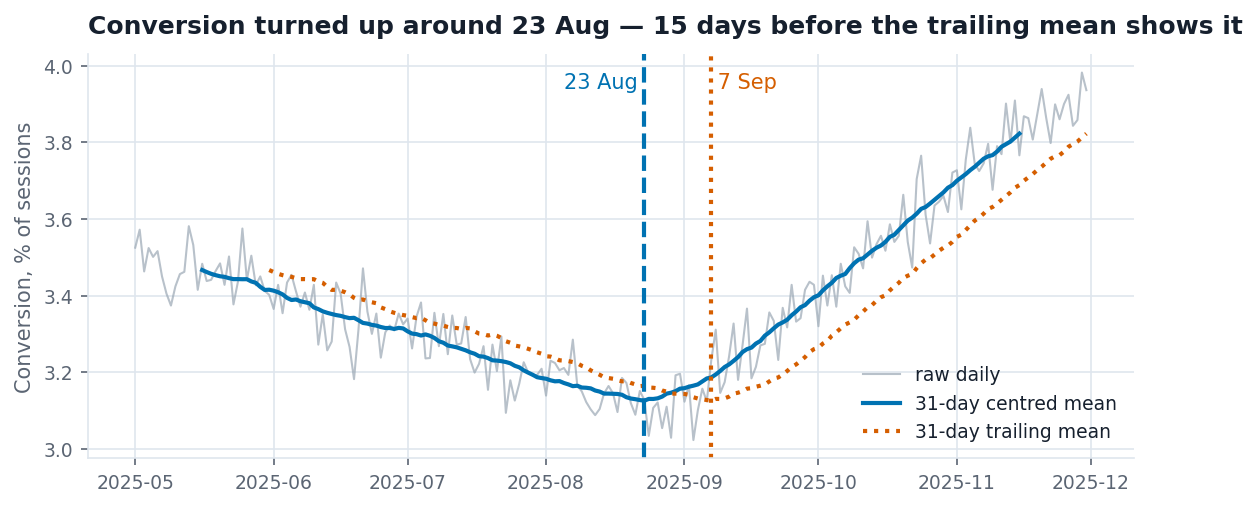

In [44]:
centred = c4.rolling(31, center=True).mean()
c_turn = centred.idxmin()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(c4.index, c4.values, color=grey, linewidth=1, alpha=0.7, label="raw daily")
ax.plot(centred.index, centred.values, color=blue, label="31-day centred mean")
ax.plot(trailing.index, trailing.values, color=orange, linestyle=":", label="31-day trailing mean")
ax.axvline(c_turn, color=blue, linestyle="--")
ax.axvline(turn, color=orange, linestyle=":")
ax.text(c_turn, c4.max(), "23 Aug ", color=blue, ha="right", va="top")
ax.text(turn, c4.max(), " 7 Sep", color=orange, va="top")
ax.set_title("Conversion turned up around 23 Aug — 15 days before the trailing mean shows it")
ax.set_ylabel("Conversion, % of sessions")
ax.legend(loc="lower right")
fig.savefig(OUT + "A4_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 5: "Revenue has fallen for six straight months"

Recipe: May to Nov 2025 only, line with markers, y from zero.

In [45]:
c5 = pd.read_csv(DATA + "case05_revenue_window.csv")
c5["month"] = pd.to_datetime(c5["month"])
c5 = c5.set_index("month")["revenue_pkr_m"]

window = c5["2025-05":"2025-11"]
print(window.round(1).tolist())
print("change:", round((window.iloc[-1] / window.iloc[0] - 1) * 100, 1), "%")

[158.8, 158.1, 143.8, 129.3, 108.0, 93.2, 92.2]
change: -41.9 %


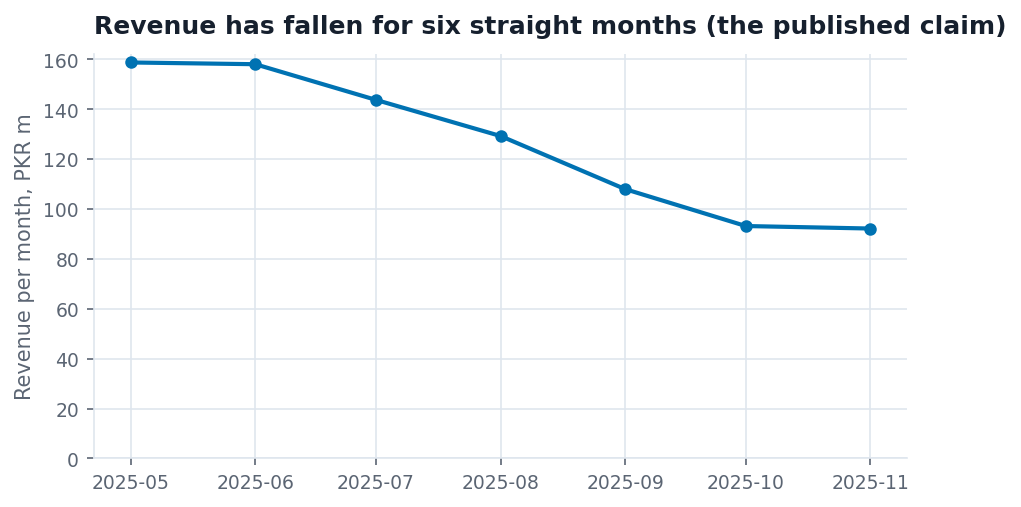

In [46]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(window.index, window.values, marker="o", color=blue)
ax.set_ylim(0, None)
ax.set_title("Revenue has fallen for six straight months (the published claim)")
ax.set_ylabel("Revenue per month, PKR m")
fig.savefig(OUT + "A5_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 7 points, 158.8 to 92.2, -41.9%. Matches.

In [47]:
print("months in the file:", len(c5), " from", c5.index.min().date(), "to", c5.index.max().date())

for year in [2023, 2024, 2025]:
    w = c5[f"{year}-05":f"{year}-11"]
    print(year, "May -> Nov:", round((w.iloc[-1] / w.iloc[0] - 1) * 100, 1), "%")

print("\naverage revenue by calendar month:")
print(c5.groupby(c5.index.month).mean().round(1).to_dict())

print("\nyearly totals:", c5.groupby(c5.index.year).sum().round(1).to_dict())
print("Nov 2025 vs Nov 2024:", round((c5["2025-11"].iloc[0] / c5["2024-11"].iloc[0] - 1) * 100, 1), "%")

months in the file: 36  from 2023-01-01 to 2025-12-01
2023 May -> Nov: -42.4 %
2024 May -> Nov: -42.8 %
2025 May -> Nov: -41.9 %

average revenue by calendar month:
{1: 92.3, 2: 112.4, 3: 128.4, 4: 140.6, 5: 145.8, 6: 144.3, 7: 132.1, 8: 117.7, 9: 97.2, 10: 87.6, 11: 84.0, 12: 88.5}

yearly totals: {2023: 1254.7, 2024: 1361.9, 2025: 1496.3}
Nov 2025 vs Nov 2024: 9.2 %


- Conclusion: the business is in decline, down 42% in six months.
- Decoy: the axis is not truncated (it starts at 0) and n is not small. The file has 36 months and only 7 are shown.
- Mechanism: the window starts at the seasonal peak (May) and ends near the low point (Nov). The same fall happens every year: -42.4% (2023), -42.8% (2024), -41.9% (2025).
- Year on year it is growing: Nov 2025 is +9.2% over Nov 2024, and yearly totals are 1,254.7, 1,361.9, 1,496.3.

Redesign: all 36 months with the window shaded, plus a cycle plot with one line per year.

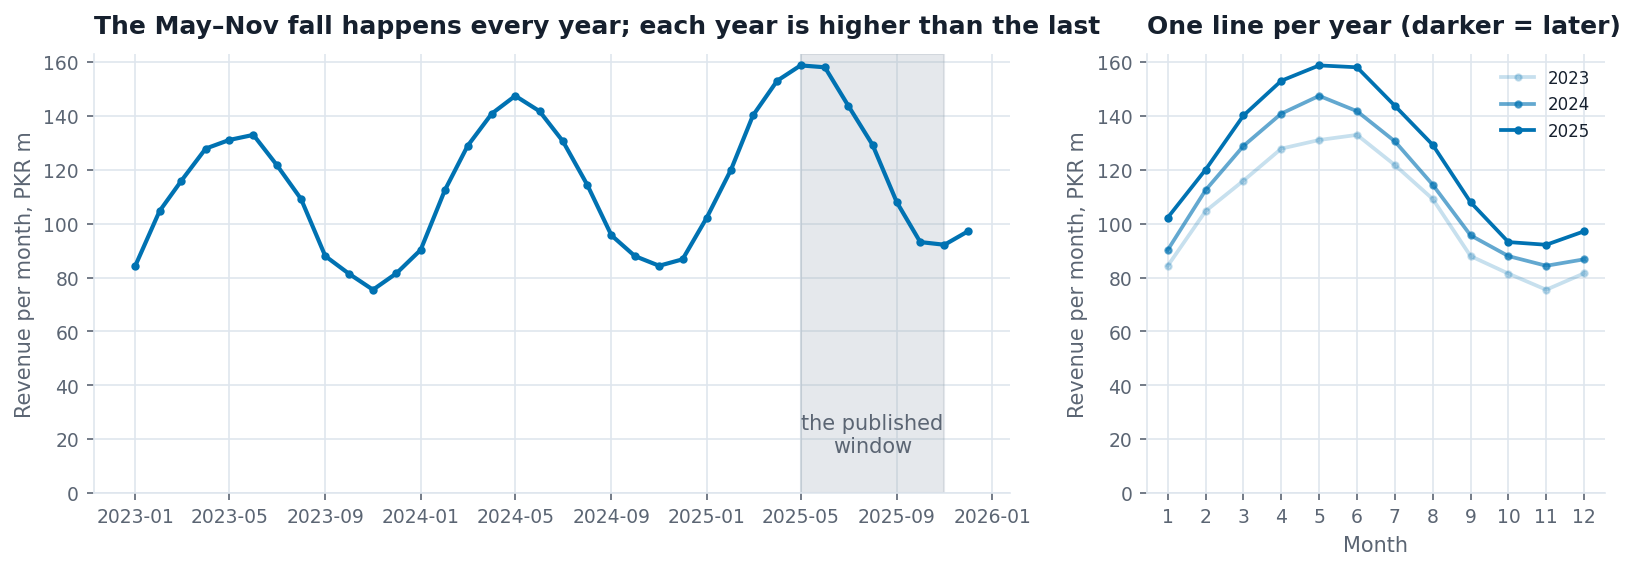

In [48]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})

ax1.plot(c5.index, c5.values, marker="o", markersize=3, color=blue)
ax1.axvspan(pd.Timestamp("2025-05-01"), pd.Timestamp("2025-11-01"), color=grey, alpha=0.25)
ax1.text(pd.Timestamp("2025-08-01"), 15, "the published\nwindow", ha="center", color=PALETTE["ink_soft"])
ax1.set_ylim(0, None)
ax1.set_ylabel("Revenue per month, PKR m")
ax1.set_title("The May–Nov fall happens every year; each year is higher than the last")

tslib.cycle_plot(ax2, c5, by="month")
ax2.set_ylim(0, None)
ax2.set_ylabel("Revenue per month, PKR m")
ax2.set_title("One line per year (darker = later)")
ax2.legend(fontsize=8)

fig.savefig(OUT + "A5_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 6: "Orders collapsed in October"

Recipe: monthly totals with `.sum()`, bars from zero.

In [49]:
c6 = pd.read_csv(DATA + "case06_monthly_partial.csv")
c6["date"] = pd.to_datetime(c6["date"])
c6 = c6.set_index("date")["orders"]

monthly = c6.resample("MS").sum()
print(monthly)
print("October as % of September:", round(monthly.iloc[-1] / monthly.iloc[-2] * 100), "%")

date
2025-01-01     9484
2025-02-01     8659
2025-03-01     9818
2025-04-01     9884
2025-05-01    10349
2025-06-01    10198
2025-07-01    10884
2025-08-01    11042
2025-09-01    10805
2025-10-01     4041
Freq: MS, Name: orders, dtype: int64
October as % of September: 37 %


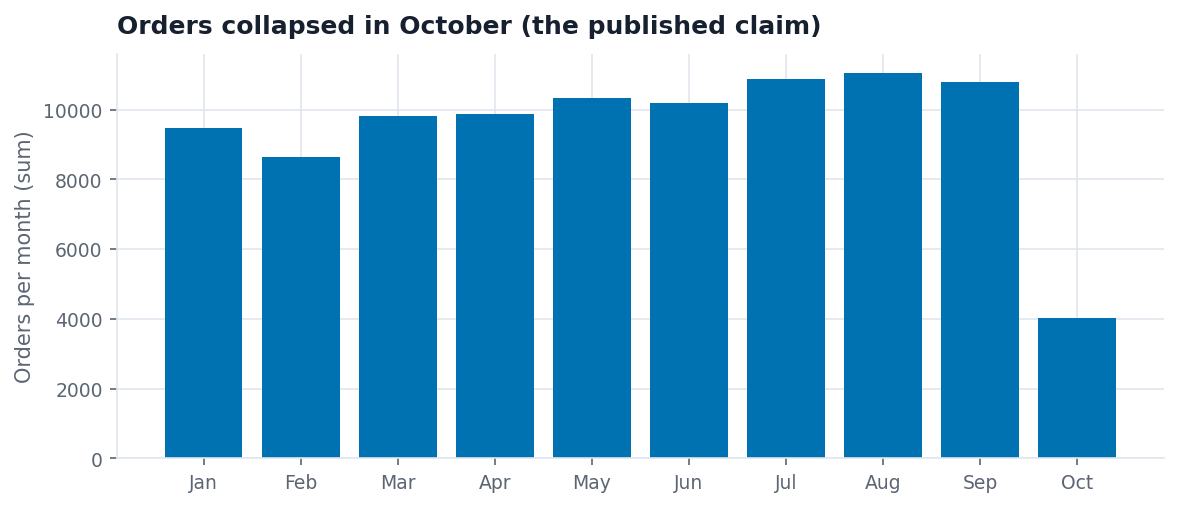

In [50]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(monthly.index.strftime("%b"), monthly.values, color=blue)
ax.set_title("Orders collapsed in October (the published claim)")
ax.set_ylabel("Orders per month (sum)")
fig.savefig(OUT + "A6_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: ten bars, Sep 10,805, Oct 4,041 (37%). Matches.

In [51]:
print(tslib.audit_index(c6, "D"))

days = c6.resample("MS").count()
per_day = (monthly / days).round(1)
print(pd.DataFrame({"orders": monthly, "days": days, "orders_per_day": per_day}))

{'dtype_ok': True, 'monotonic': True, 'n_rows': 284, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2025-01-01 00:00:00', '2025-10-11 00:00:00'), 'partial_tail': True, 'tail_period': '2025-10', 'tail_count': 11}
            orders  days  orders_per_day
date                                    
2025-01-01    9484    31           305.9
2025-02-01    8659    28           309.2
2025-03-01    9818    31           316.7
2025-04-01    9884    30           329.5
2025-05-01   10349    31           333.8
2025-06-01   10198    30           339.9
2025-07-01   10884    31           351.1
2025-08-01   11042    31           356.2
2025-09-01   10805    30           360.2
2025-10-01    4041    11           367.4


- Conclusion: orders dropped to about a third in October.
- Decoy: maybe days are missing or duplicated. No, `audit_index` shows 0 duplicates and 0 missing days.
- Mechanism: the data ends on 11 October, so October has only 11 days and gets compared with 30-day months.
- Per day, October has 367.4 orders, the highest of the year (Sep was 360.2).

Redesign: orders per day, with October marked as partial.

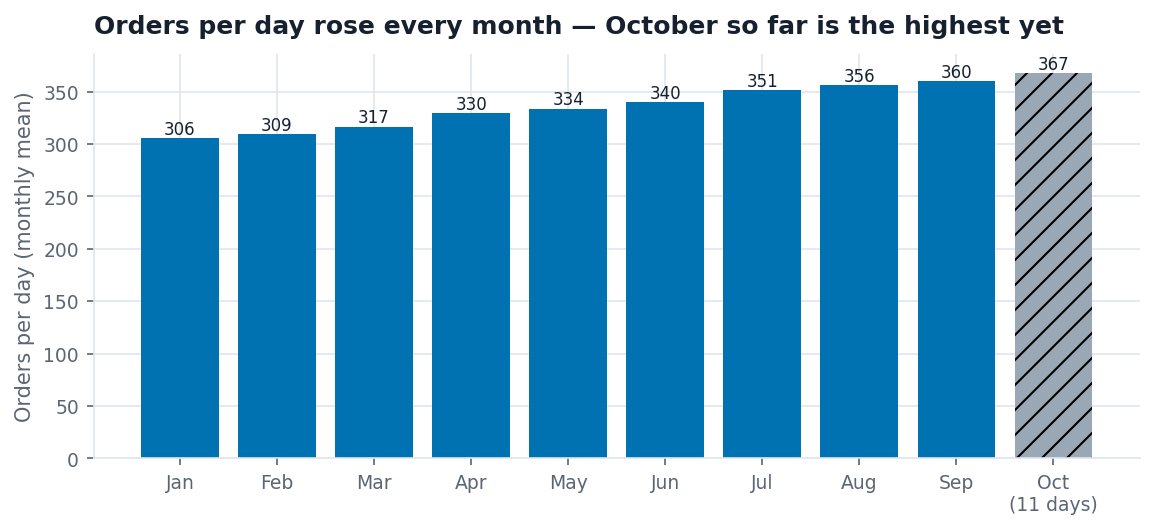

In [52]:
labels = list(monthly.index.strftime("%b"))
labels[-1] = "Oct\n(11 days)"
colors = [blue] * (len(per_day) - 1) + [grey]

fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(labels, per_day.values, color=colors)
bars[-1].set_hatch("//")
ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.set_title("Orders per day rose every month — October so far is the highest yet")
ax.set_ylabel("Orders per day (monthly mean)")
fig.savefig(OUT + "A6_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 7: "Product D has been erratic since mid-2024"

Recipe: stacked area, `product_a` at the bottom and `product_d` on top.

In [53]:
c7 = pd.read_csv(DATA + "case07_stacked_products.csv")
c7["month"] = pd.to_datetime(c7["month"])
c7 = c7.set_index("month")

total = c7.sum(axis=1)
print("total envelope:", round(total.min(), 1), "to", round(total.max(), 1))

total envelope: 548.3 to 708.7


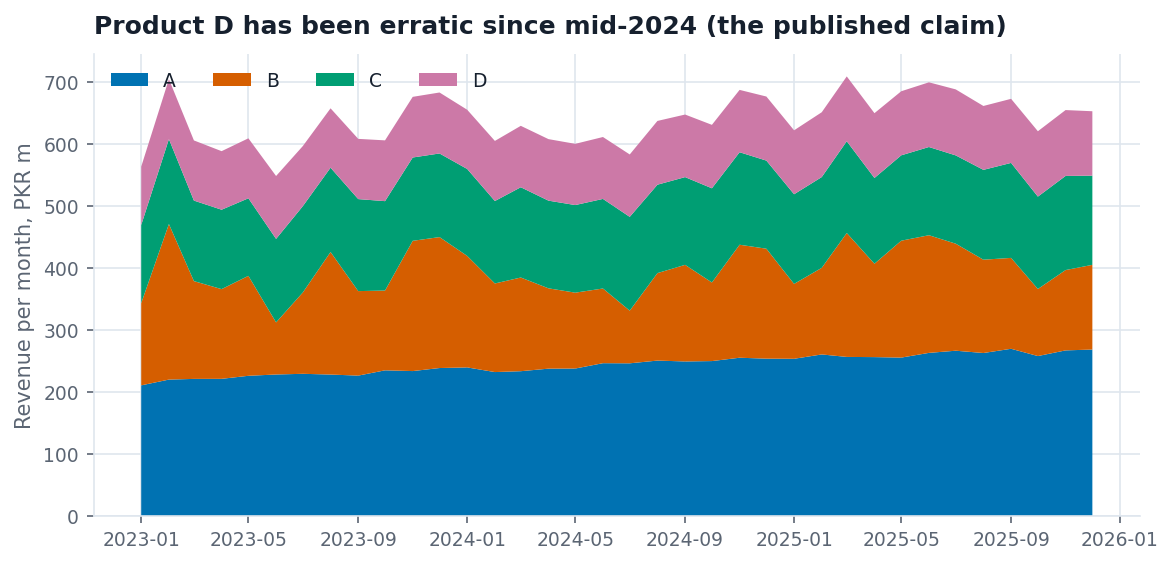

In [54]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.stackplot(c7.index, c7["product_a"], c7["product_b"], c7["product_c"], c7["product_d"],
             labels=["A", "B", "C", "D"], colors=[blue, orange, green, pink])
ax.set_title("Product D has been erratic since mid-2024 (the published claim)")
ax.set_ylabel("Revenue per month, PKR m")
ax.legend(loc="upper left", ncol=4)
fig.savefig(OUT + "A7_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: total between about 548 and 709. Matches.

Checking how much each product changes from month to month.

In [55]:
changes = c7.diff()
print("std of month-to-month change, whole period:")
print(changes.std().round(1))
print("\nsince July 2024:")
print(changes["2024-07":].std().round(1))

std of month-to-month change, whole period:
product_a     4.7
product_b    45.8
product_c     6.4
product_d     2.0
dtype: float64

since July 2024:
product_a     5.1
product_b    36.3
product_c     5.8
product_d     1.8
dtype: float64


- Conclusion: product D jumps around a lot.
- Decoy: maybe D really is volatile. No, D has the smallest month-to-month std of the four (2.0), and it is not higher after mid-2024.
- Mechanism: in a stacked area each band sits on the bands below it. `product_b` has a std of 45.8 and sits under C and D, so its swings push D's top edge up and down.

Redesign: one small panel per product, each from zero, same y scale.

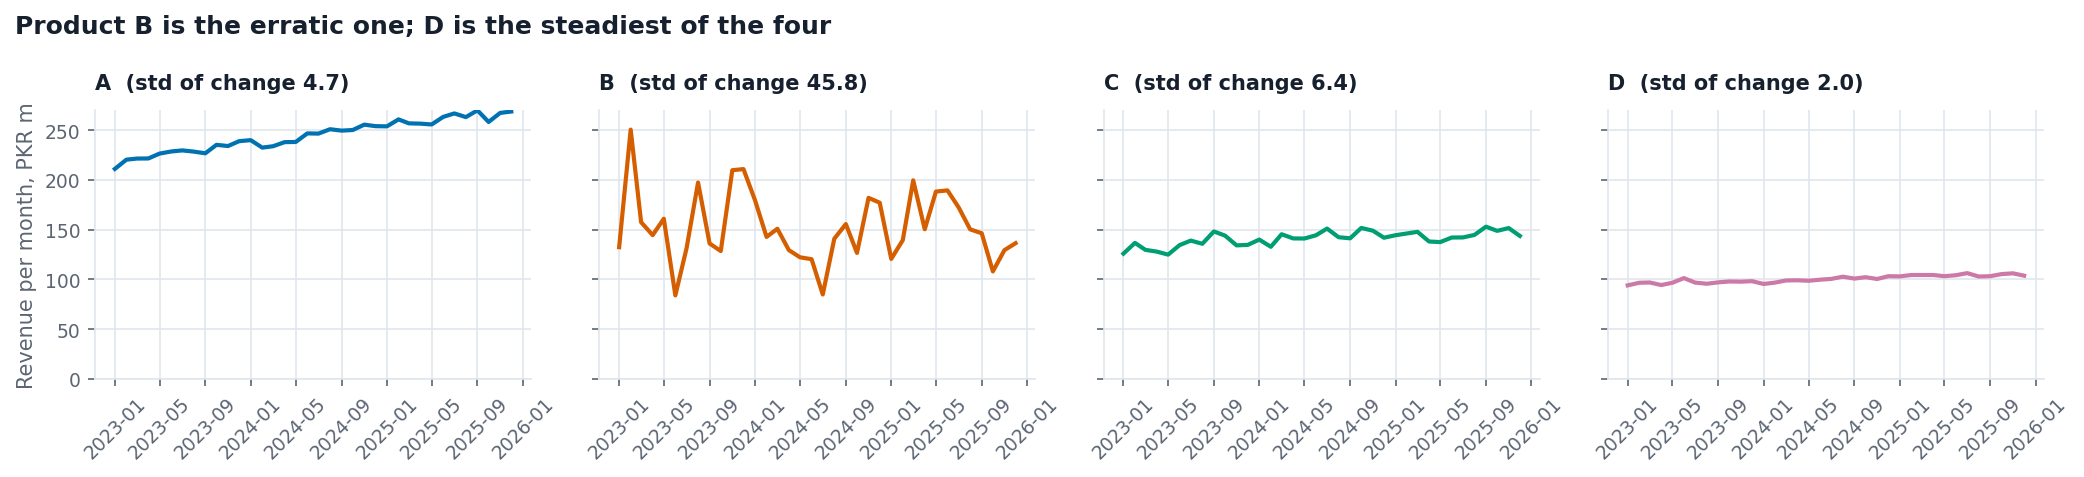

In [56]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
names = ["product_a", "product_b", "product_c", "product_d"]
cols = [blue, orange, green, pink]

for ax, name, col in zip(axes, names, cols):
    ax.plot(c7.index, c7[name], color=col)
    ax.set_title(f"{name[-1].upper()}  (std of change {changes[name].std():.1f})", fontsize=10)
    ax.set_ylim(0, 270)
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("Revenue per month, PKR m")
fig.suptitle("Product B is the erratic one; D is the steadiest of the four", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT + "A7_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 8: "Paid search drives 43% of our customers"

Recipe: share of `True` in each `touch_*` column, as a four-slice pie.

In [57]:
c8 = pd.read_csv(DATA + "case08_channel_attrib.csv")
touch = ["touch_search", "touch_social", "touch_email", "touch_direct"]

shares8 = c8[touch].sum() / len(c8) * 100
print(shares8.round(1))
print("sum of the four shares:", round(shares8.sum(), 1), "%")

touch_search    42.6
touch_social    32.3
touch_email     27.5
touch_direct    28.6
dtype: float64
sum of the four shares: 131.0 %


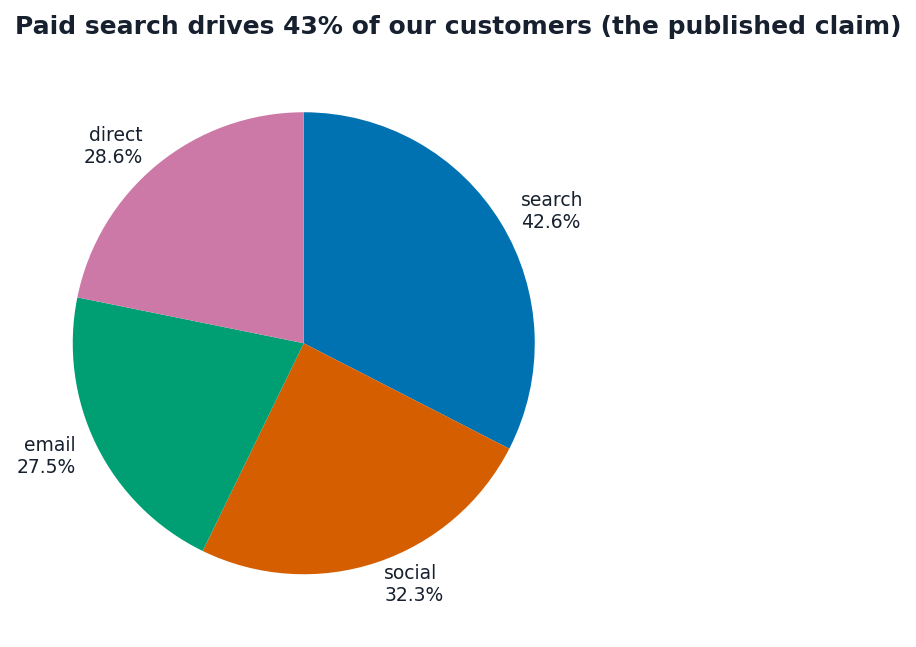

In [58]:
fig, ax = plt.subplots(figsize=(5, 5))
names8 = [t.replace("touch_", "") for t in touch]
labels8 = [f"{n}\n{v:.1f}%" for n, v in zip(names8, shares8)]
ax.pie(shares8, labels=labels8, colors=[blue, orange, green, pink], startangle=90, counterclock=False)
ax.set_title("Paid search drives 43% of our customers (the published claim)")
fig.savefig(OUT + "A8_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 42.6%, 32.3%, 27.5%, 28.6%. Matches, but they add up to 131%.

In [59]:
check8 = tslib.exclusivity_check(c8, touch)
print(check8)

n_channels = c8[touch].sum(axis=1)
print(n_channels.value_counts().sort_index())

only_one = c8[n_channels == 1]
only_share = only_one[touch].sum() / len(c8) * 100
print("\ncustomers touched ONLY by this channel (% of all customers):")
print(only_share.round(1))

{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}
1    2895
2     980
3     116
4       9
Name: count, dtype: int64

customers touched ONLY by this channel (% of all customers):
touch_search    25.9
touch_social    17.8
touch_email     13.8
touch_direct    14.8
dtype: float64


- Conclusion: search brings 43% of customers, the biggest slice.
- Decoy: maybe it is just rounding. No, the sum is 131%, which rounding cannot explain.
- Mechanism: the channels are not exclusive. 1,105 customers (27.6%) were touched by 2 or more channels, so they are counted more than once.
- Also, `pie()` rescales to 100%, so the search slice is drawn as 32.5% while its label says 42.6%. Only 25.9% came through search alone.

Redesign: no pie. Bars of reach out of 100%, next to "this channel only".

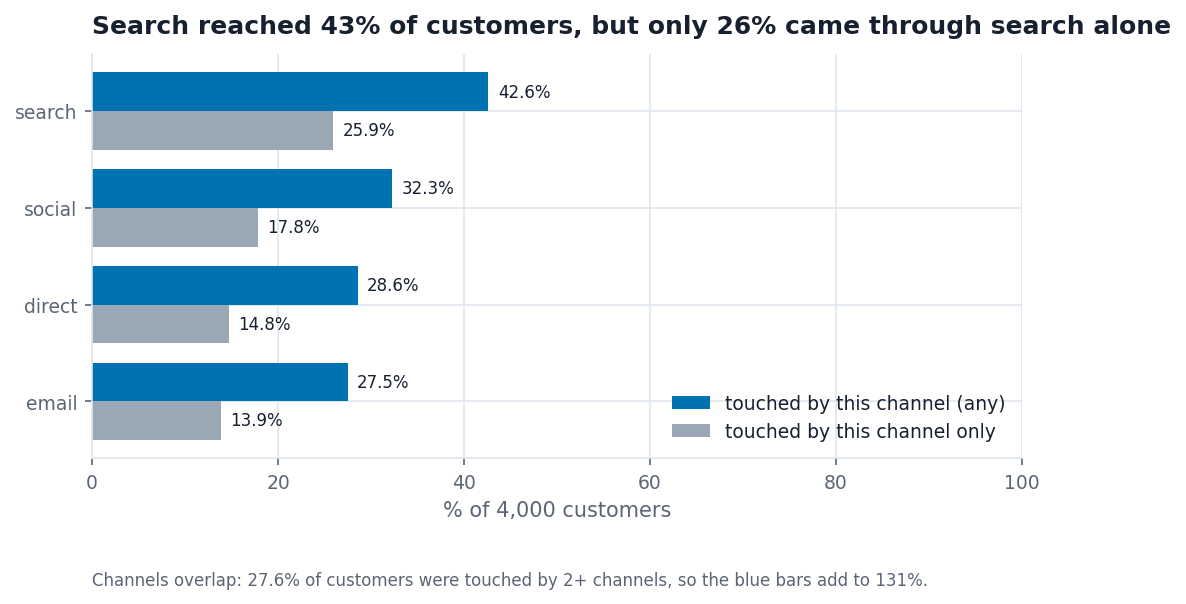

In [60]:
order = shares8.sort_values().index
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(y + 0.2, shares8[order], height=0.4, color=blue, label="touched by this channel (any)")
ax.barh(y - 0.2, only_share[order], height=0.4, color=grey, label="touched by this channel only")
for i, name in enumerate(order):
    ax.text(shares8[name] + 1, i + 0.2, f"{shares8[name]:.1f}%", va="center", fontsize=8)
    ax.text(only_share[name] + 1, i - 0.2, f"{only_share[name]:.1f}%", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels([n.replace("touch_", "") for n in order])
ax.set_xlim(0, 100)
ax.set_xlabel("% of 4,000 customers")
ax.set_title("Search reached 43% of customers, but only 26% came through search alone")
ax.legend(loc="lower right")
ax.text(0, -1.9, "Channels overlap: 27.6% of customers were touched by 2+ channels, so the blue bars add to 131%.",
        fontsize=8, color=PALETTE["ink_soft"])
fig.savefig(OUT + "A8_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Case 9: "Premium is now 38% of revenue, a record"

Recipe: premium / total per quarter, line from zero, label the last point.

In [61]:
c9 = pd.read_csv(DATA + "case09_premium_share.csv")
c9["share"] = c9["premium_revenue_pkr_m"] / c9["total_revenue_pkr_m"] * 100
print(c9.round(1))

  quarter  total_revenue_pkr_m  premium_revenue_pkr_m  share
0  2024Q1               1000.0                  240.0   24.0
1  2024Q2                940.0                  236.9   25.2
2  2024Q3                870.0                  233.2   26.8
3  2024Q4                800.0                  228.0   28.5
4  2025Q1                745.0                  227.2   30.5
5  2025Q2                700.0                  227.5   32.5
6  2025Q3                650.0                  228.8   35.2
7  2025Q4                600.0                  228.0   38.0


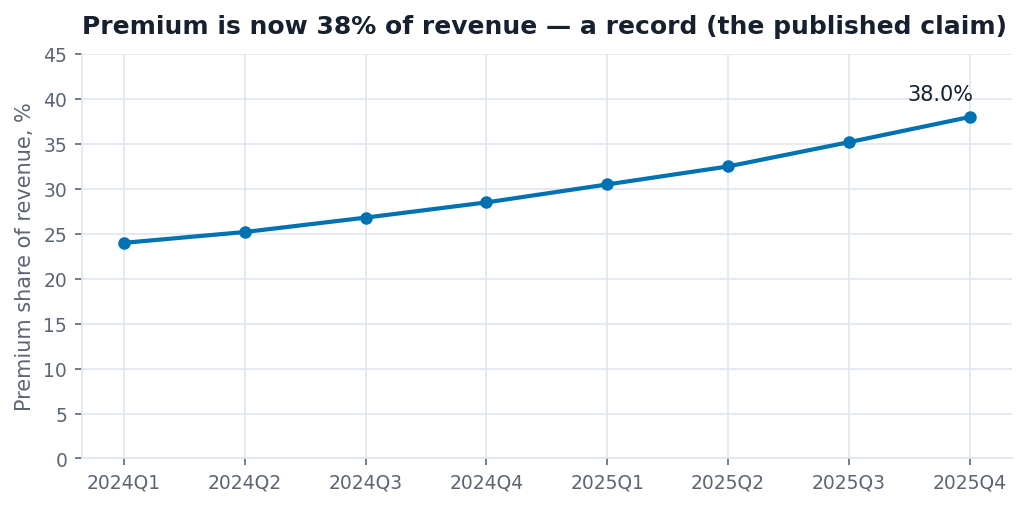

In [62]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(c9["quarter"], c9["share"], marker="o", color=blue)
ax.annotate(f"{c9['share'].iloc[-1]:.1f}%", (7, c9["share"].iloc[-1]), xytext=(-30, 8), textcoords="offset points")
ax.set_ylim(0, 45)
ax.set_title("Premium is now 38% of revenue — a record (the published claim)")
ax.set_ylabel("Premium share of revenue, %")
fig.savefig(OUT + "A9_rebuild.png", dpi=300, bbox_inches="tight")
plt.show()

Self-check: 24.0% to 38.0%. Matches.

In [63]:
first9 = c9.iloc[0]
last9 = c9.iloc[-1]
print("total revenue:   ", first9["total_revenue_pkr_m"], "->", last9["total_revenue_pkr_m"],
      round((last9["total_revenue_pkr_m"] / first9["total_revenue_pkr_m"] - 1) * 100, 1), "%")
print("premium revenue: ", first9["premium_revenue_pkr_m"], "->", last9["premium_revenue_pkr_m"],
      round((last9["premium_revenue_pkr_m"] / first9["premium_revenue_pkr_m"] - 1) * 100, 1), "%")
print("premium max quarter:", c9.loc[c9["premium_revenue_pkr_m"].idxmax(), "quarter"])

total revenue:    1000.0 -> 600.0 -40.0 %
premium revenue:  240.0 -> 228.0 -5.0 %
premium max quarter: 2024Q1


- Conclusion: premium is growing and doing great.
- Decoy: maybe the share is calculated wrong. No, 228 / 600 = 38.0%. The chart is not wrong, it is incomplete.
- Mechanism: a rising share of a falling total. Total revenue fell 40% (1,000 to 600) and premium also fell 5% (240 to 228). Premium's best quarter was the first one.

Redesign: the same share chart, with the actual revenue next to it (two panels, no dual axis).

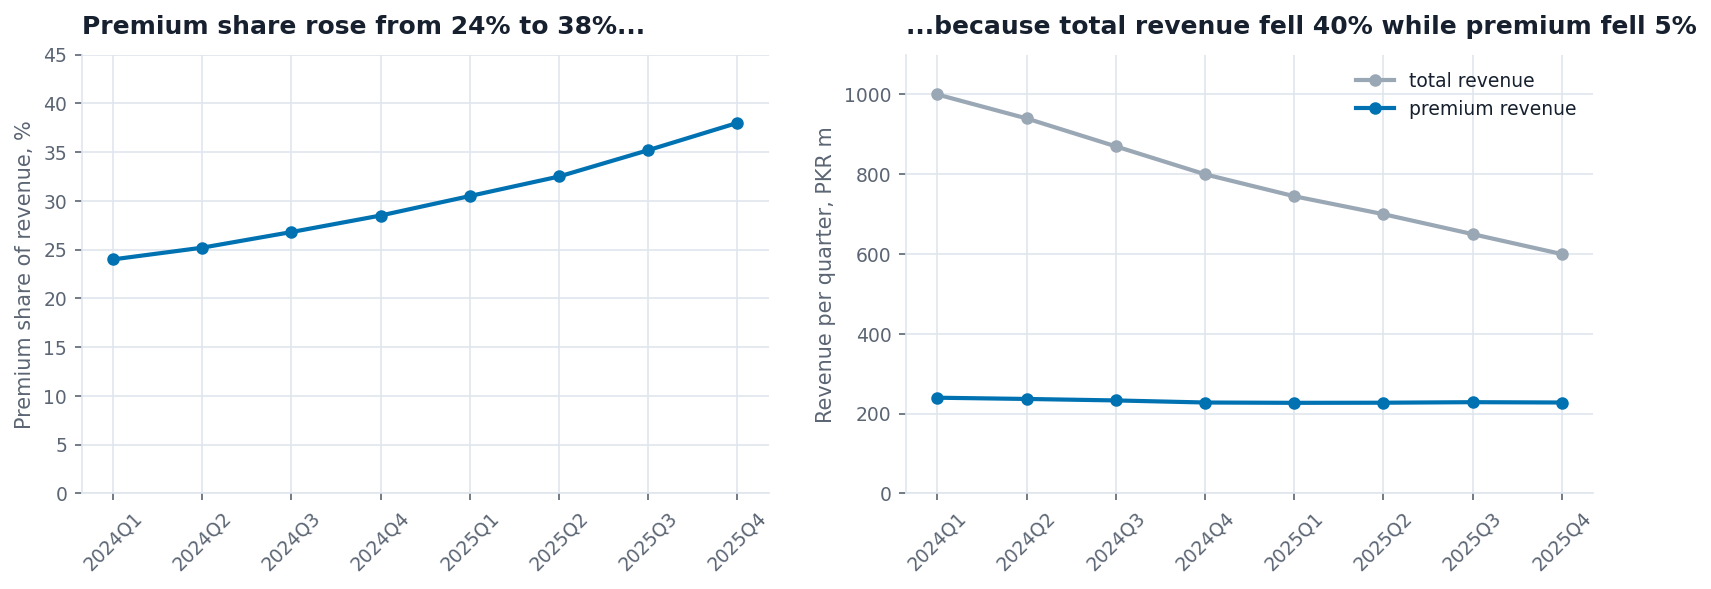

In [64]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))

ax1.plot(c9["quarter"], c9["share"], marker="o", color=blue)
ax1.set_ylim(0, 45)
ax1.set_ylabel("Premium share of revenue, %")
ax1.set_title("Premium share rose from 24% to 38%...")

ax2.plot(c9["quarter"], c9["total_revenue_pkr_m"], marker="o", color=grey, label="total revenue")
ax2.plot(c9["quarter"], c9["premium_revenue_pkr_m"], marker="o", color=blue, label="premium revenue")
ax2.set_ylim(0, 1100)
ax2.set_ylabel("Revenue per quarter, PKR m")
ax2.set_title("...because total revenue fell 40% while premium fell 5%")
ax2.legend()

for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=45)

fig.savefig(OUT + "A9_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

---
# Part D (step 1): Clean `sessions_hourly.csv`

Part B uses the cleaned daily series, so I clean first. These are the four calls from the brief.

In [65]:
df = pd.read_csv(DATA + "sessions_hourly.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ts           12670 non-null  object
 1   sessions     12670 non-null  int64 
 2   orders       12670 non-null  int64 
 3   revenue_pkr  12670 non-null  int64 
 4   device       12670 non-null  object
dtypes: int64(3), object(2)
memory usage: 495.1+ KB


In [66]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sessions,12670.0,947.951381,646.882994,-1.0,435.0,756.0,1368.00,9811.0
orders,12670.0,30.016732,20.089492,4.0,14.0,24.0,42.00,304.0
revenue_pkr,12670.0,132564.968824,100150.706234,10350.0,58036.5,102359.0,182232.25,1652881.0


In [67]:
df["device"].value_counts()

,count
device,
Mobile,6994
Desktop,3452
mobile,883
Tablet,777
desktop,318
MOBILE,246


In [68]:
df["ts"].head(10).tolist()

['2024-04-29 11:00:00',
 '2024-10-26 05:00:00',
 '2025-08-04 20:00:00',
 '2024-10-05 19:00:00',
 '2025-01-22 20:00:00',
 '05/10/2024 09:00',
 '2024-08-11 15:00:00',
 '12/04/2025 10:00',
 '2024-07-24 02:00:00',
 '2025-03-27 11:00:00']

What these show:
1. `ts` is text, not datetime.
2. `sessions` has a min of -1, a placeholder value.
3. `device` has different cases (Mobile, mobile, MOBILE).
4. `ts` has two formats and the rows are not in order.

### Fault 1: two date formats

In [69]:
iso = df["ts"].str.match(r"^\d{4}-")
print("YYYY-MM-DD rows:", iso.sum(), "   dd/mm/yyyy rows:", (~iso).sum())

other = df.loc[~iso, "ts"]
first_num = other.str[:2].astype(int)
second_num = other.str[3:5].astype(int)
print("slash rows where the 1st number > 12:", (first_num > 12).sum())
print("slash rows where the 2nd number > 12:", (second_num > 12).sum())

YYYY-MM-DD rows: 9019    dd/mm/yyyy rows: 3651
slash rows where the 1st number > 12: 2151
slash rows where the 2nd number > 12: 0


In the slash rows the first number goes above 12 but the second never does, so it is day/month/year.

Now checking what `format="mixed"` does.

In [70]:
mixed = pd.to_datetime(df["ts"], format="mixed")
print("format='mixed' range:", mixed.min(), "to", mixed.max())

part1 = pd.to_datetime(df["ts"].where(iso), format="%Y-%m-%d %H:%M:%S")
part2 = pd.to_datetime(df["ts"].where(~iso), format="%d/%m/%Y %H:%M")
df["time"] = part1.fillna(part2)

print("my parse range:      ", df["time"].min(), "to", df["time"].max())
print("rows not parsed:", df["time"].isna().sum())
print("rows that 'mixed' put on a different date:", (mixed != df["time"]).sum())

format='mixed' range: 2024-01-04 01:00:00 to 2025-12-08 22:00:00
my parse range:       2024-04-01 00:00:00 to 2025-09-11 23:00:00
rows not parsed: 0
rows that 'mixed' put on a different date: 1382


`format="mixed"` reads `05/10/2024` as May 10, so 1,382 rows move to the wrong date.
My parse gives 1 Apr 2024 to 11 Sep 2025, which matches the data dictionary (starts April 2024).

### Fault 2: device labels

In [71]:
df["device"] = df["device"].str.strip().str.title()
df["device"].value_counts()

,count
device,
Mobile,8123
Desktop,3770
Tablet,777


### Faults 3 and 4: unsorted index and duplicates

These only show after the index is a real DatetimeIndex.

In [72]:
df = df.set_index("time")
print("sorted before sort_index?", df.index.is_monotonic_increasing)
df = df.sort_index()

audit_hourly = tslib.audit_index(df, "h")
audit_hourly

sorted before sort_index? False


{'dtype_ok': True,
 'monotonic': True,
 'n_rows': 12670,
 'n_duplicated': 286,
 'n_missing': 312,
 'missing_dates': ['2024-05-18 00:00:00',
  '2024-05-18 01:00:00',
  '2024-05-18 02:00:00',
  '2024-05-18 03:00:00',
  '2024-05-18 04:00:00',
  '2024-05-18 05:00:00',
  '2024-05-18 06:00:00',
  '2024-05-18 07:00:00',
  '2024-05-18 08:00:00',
  '2024-05-18 09:00:00',
  '2024-05-18 10:00:00',
  '2024-05-18 11:00:00'],
 'span': ('2024-04-01 00:00:00', '2025-09-11 23:00:00'),
 'partial_tail': False,
 'tail_period': '2025-09-11',
 'tail_count': 24}

In [73]:
dupes = df[df.index.duplicated(keep=False)]
same = dupes.drop(columns="ts").reset_index().duplicated(keep=False).sum()
print("rows sharing a timestamp:", len(dupes), "  of those, identical in every value:", same)

rows_before = len(df)
df = df[~df.index.duplicated(keep="first")]
print("duplicates removed:", rows_before - len(df), "  rows:", rows_before, "->", len(df))

rows sharing a timestamp: 572   of those, identical in every value: 572
duplicates removed: 286   rows: 12670 -> 12384


All 572 rows that share a timestamp are exact copies, so I keep the first one. 286 rows removed.

### Fault 5: the -1 values

In [74]:
bad = df["sessions"] < 0
print("hours with sessions = -1:", bad.sum())
print("orders in those hours (min, max):", df.loc[bad, "orders"].min(), df.loc[bad, "orders"].max())

df["sessions"] = df["sessions"].where(~bad)
print("sessions missing now:", df["sessions"].isna().sum())

hours with sessions = -1: 287
orders in those hours (min, max): 5 83
sessions missing now: 287


These hours still have orders (5 to 83), so the hour was real and only the sessions count failed. I set them to NaN and keep the rows.

### Fault 6: missing days

In [75]:
audit_clean = tslib.audit_index(df, "h")
print("missing hours:", audit_clean["n_missing"])

rows_per_day = df["sessions"].resample("D").size()
print("rows per day:", rows_per_day.value_counts().to_dict())
missing_days = rows_per_day[rows_per_day == 0].index
print("days with no data at all:", len(missing_days))
print([d.strftime("%Y-%m-%d") for d in missing_days])

missing hours: 312
rows per day: {24: 516, 0: 13}
days with no data at all: 13
['2024-05-18', '2024-07-02', '2024-07-03', '2024-09-27', '2024-11-11', '2024-12-25', '2025-01-01', '2025-02-14', '2025-03-30', '2025-03-31', '2025-06-07', '2025-07-19', '2025-08-23']


312 missing hours = 13 full days. Every recorded day has all 24 rows.
There is no daylight saving in Pakistan, so these are collector outages. I leave them as NaN so the line breaks.

### Partial last month

In [76]:
print("last timestamp:", df.index.max())
print("rows in September 2025:", len(df.loc["2025-09"]), "(a full month would be 720)")

last timestamp: 2025-09-11 23:00:00
rows in September 2025: 264 (a full month would be 720)


The data stops on 11 Sep 2025, so September is partial. I cut at 31 Aug 2025, which leaves 17 full months.

### Daily series
Sessions are a flow, so daily = sum of hours. To handle the -1 hours, my rule is daily = mean of valid hours x 24. A day with no data stays NaN.

In [77]:
hourly = df.loc[:"2025-08-31", "sessions"]

daily = hourly.resample("D").mean() * 24
plain_sum = hourly.resample("D").sum(min_count=1)

print("days:", len(daily), "  NaN days (outages):", daily.isna().sum())
print("days with 1-3 sentinel hours:", ((hourly.resample("D").count() < 24) & (hourly.resample("D").count() > 0)).sum())
print("Black Friday 2024-11-29:", daily["2024-11-29"])
print("median daily sessions, plain sum vs my rule:", plain_sum.median(), "vs", round(daily.median()))
print(tslib.audit_index(daily, "D"))

days: 518   NaN days (outages): 13
days with 1-3 sentinel hours: 215
Black Friday 2024-11-29: 113710.0
median daily sessions, plain sum vs my rule: 22068.0 vs 22627
{'dtype_ok': True, 'monotonic': True, 'n_rows': 518, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2024-04-01 00:00:00', '2025-08-31 00:00:00'), 'partial_tail': False, 'tail_period': '2025-08', 'tail_count': 31}


---
# Part B: Smoothing, windows and panel shape

### B1: The window is a hypothesis

In [78]:
report = tslib.window_report(daily, windows=(7, 28, 91))
report

,window,raw_sd,smoothed_sd,variation_removed_pct,periods_lost_each_end
0,7,6818.197,4646.1871,31.9,3
1,28,6818.197,4430.7976,35.0,14
2,91,6818.197,4152.4932,39.1,45


- 7 days: removes the weekly cycle. 31.9% of variation removed, 3 days lost each end.
- 28 days: weekly cycle plus monthly noise like Black Friday week. 35.0%, 14 days lost.
- 91 days: also starts removing the seasonal turn itself. 39.1%, 45 days lost.

The numbers are low because most of the variation is the slow trend.

I use 7 days (centred) in Part D because the cycle hiding the trend is weekly, and 7 days covers each weekday once.

### B2: Three smoothers against one spike

In [79]:
bf = "2024-11-29"
mean14 = daily.rolling(14, center=True, min_periods=7).mean()
median14 = daily.rolling(14, center=True, min_periods=7).median()
ewma14 = daily.ewm(span=14).mean()

print("raw on Black Friday:      ", round(daily[bf]))
print("14-day centred mean:      ", round(mean14[bf]))
print("14-day centred median:    ", round(median14[bf]))
print("EWMA (span 14):           ", round(ewma14[bf]))
print("fortnight median (raw):   ", round(daily["2024-11-22":"2024-12-05"].median()))

raw on Black Friday:       113710
14-day centred mean:       33382
14-day centred median:     24780
EWMA (span 14):            38229
fortnight median (raw):    24780


- Mean: about 33,400. One big day pulls it up a lot.
- Median: about 24,800. It ignores the spike (the brief says about 24,600).
- EWMA: about 38,200. It gives the most weight to the latest day.

For a monitoring dashboard I would use EWMA, because it only needs past data and reacts fast. For a quarterly report I would use the centred median, because one-day events don't move it.

### B3: Decompose it
`seasonal_decompose` can't take NaN, so here only I fill the 13 outage days by interpolation. These filled values are not used in any figure.

In [80]:
filled = daily.interpolate()
print("days filled for decomposition only:", daily.isna().sum())

dec7 = seasonal_decompose(filled, model="additive", period=7)
seasonal = dec7.seasonal
print("weekly seasonal amplitude (peak - trough):", round(seasonal.max() - seasonal.min()))
print(seasonal.groupby(seasonal.index.day_name()).mean().round(0).sort_values())

print("\nlargest residual:", dec7.resid.abs().idxmax().date(), " value:", round(dec7.resid[dec7.resid.abs().idxmax()]))
print(dec7.resid.abs().sort_values(ascending=False).head(5).round(0))

days filled for decomposition only: 13
weekly seasonal amplitude (peak - trough): 7569
time
Thursday    -2378.0
Wednesday   -2330.0
Tuesday     -2274.0
Monday      -2163.0
Friday       -947.0
Saturday     4902.0
Sunday       5191.0
Name: seasonal, dtype: float64

largest residual: 2024-11-29  value: 74659
time
2024-11-29    74659.0
2024-12-02    13047.0
2024-11-26    13001.0
2024-11-27    12642.0
2024-11-30    12446.0
Name: resid, dtype: float64


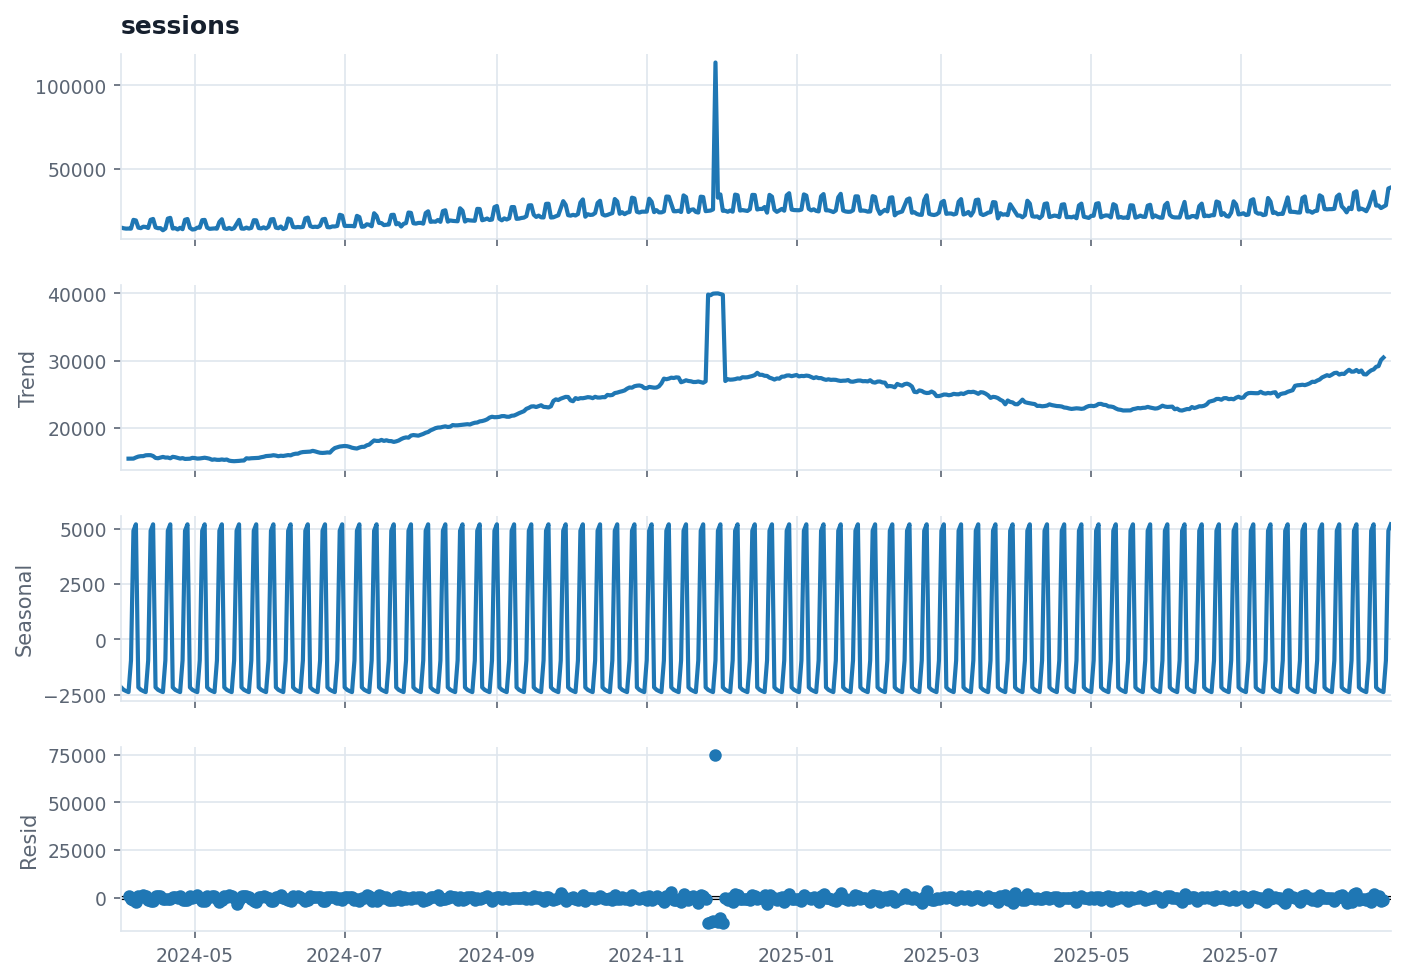

In [81]:
fig = dec7.plot()
fig.set_size_inches(10, 7)
fig.savefig(OUT + "B3_decompose.png", dpi=300, bbox_inches="tight")
plt.show()

In [82]:
try:
    dec365 = seasonal_decompose(filled, model="additive", period=365)
except ValueError as e:
    print("period=365 failed:", e)

period=365 failed: x must have 2 complete cycles requires 730 observations. x only has 518 observation(s)


- The weekly seasonal amplitude is about 7,600 sessions/day (Thursday lowest, Sunday highest).
- The largest residual is 2024-11-29, Black Friday (about +74,700).
- `period=365` does not run, because it needs 730 days and we have 518. With two years of data, the yearly pattern (Nov peak, spring dip) would move into `seasonal`.

### B4: Trailing or centred

In [83]:
lag31 = tslib.lag_at_turn(filled, 31, how="max")
print(lag31)

{'window': 31, 'trailing_turn': Timestamp('2024-12-29 00:00:00'), 'centred_turn': Timestamp('2024-12-14 00:00:00'), 'lag_periods': 15, 'half_window': 15}


I used the peak (`how="max"`) because the turn leadership misses is the late-2024 top.
The centred mean peaks on 2024-12-14 and the trailing one on 2024-12-29: a 15-day lag, the same as the half-window.

A live dashboard has to use the trailing mean, because a centred mean needs future days. Caption: "31-day trailing mean, turns show about 15 days late."

### B5: The window is a claim
For each start month and length (7 to 91 days), I take that slice, fit a line and check whether the slope is up or down.

In [84]:
starts = pd.date_range("2024-04-01", periods=12, freq="MS")
lengths = [7, 14, 28, 56, 91]

results = []
for start in starts:
    for n_days in lengths:
        piece = daily[start : start + pd.Timedelta(days=n_days - 1)].dropna()
        x = (piece.index - piece.index[0]).days
        slope = np.polyfit(x, piece.values, 1)[0]
        results.append({"start": start.strftime("%Y-%m"), "days": n_days, "slope": round(slope, 1)})

results = pd.DataFrame(results)
results["direction"] = np.where(results["slope"] > 0, "rising", "falling")

print(results["direction"].value_counts())
results.pivot(index="start", columns="days", values="direction")

direction
rising     34
falling    26
Name: count, dtype: int64


days,7,14,28,56,91
start,,,,,
2024-04,rising,rising,rising,rising,rising
2024-05,rising,rising,rising,rising,rising
2024-06,falling,falling,falling,rising,rising
2024-07,rising,rising,rising,rising,rising
2024-08,falling,rising,rising,rising,rising
2024-09,falling,rising,rising,rising,rising
2024-10,rising,rising,rising,rising,rising
2024-11,falling,falling,falling,rising,falling
2024-12,falling,rising,rising,falling,falling


34 combinations are rising and 26 are falling, all on the same series.

- Lie Factor = effect shown / effect in the data. It assumes there is one true effect to divide by.
- Here the trend changes with the window, so there is no single true value and the formula can't be used.
- Honest substitute: fix the window before looking, show the full series, and report the spread (34 up, 26 down).

---
# Part C: Part-to-whole legality, and the ranking

### C1: The three conditions, tested in code

In [85]:
print("1) case08 touch_* columns")
print(tslib.exclusivity_check(c8, touch))

1) case08 touch_* columns
{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}


In [86]:
s8 = pd.read_csv(DATA + "shares_eight.csv")
print("2) shares_eight.csv")
print("sum:", s8["share_pct"].sum())
assert abs(s8["share_pct"].sum() - 100) < 1e-6
print("each sub-category once?", s8["subcategory"].is_unique)

catalogue_raw = pd.read_csv(DATA + "revenue_catalogue.csv")
print("sub-categories in the catalogue:", catalogue_raw["subcategory"].nunique())

2) shares_eight.csv
sum: 100.0
each sub-category once? True
sub-categories in the catalogue: 8


In [87]:
q4 = c9[c9["quarter"] == "2025Q4"].iloc[0]
premium = q4["premium_revenue_pkr_m"]
other_rev = q4["total_revenue_pkr_m"] - premium
two = pd.Series({"premium": premium, "other": other_rev}) / q4["total_revenue_pkr_m"] * 100
print("3) 2025Q4 premium vs other")
print(two.round(1))
assert abs(two.sum() - 100) < 1e-6

3) 2025Q4 premium vs other
premium    38.0
other      62.0
dtype: float64


- case08 touch columns: not exclusive (sum is 131%), no real whole. Neither pie nor stacked bar. Separate reach bars are fine.
- shares_eight: exclusive, sums to 100, and the 8 are the whole catalogue. A pie is allowed, but bars are better because C, H and G are close.
- 2025Q4 premium vs other: exclusive and sums to 100, but the question is whether premium grew, which one quarter can't show. So the pie answers the wrong question. Use revenue over time.

### C2: The ranking experiment
Stimuli: a pie with no numbers in file order, and sorted bars with no numbers. One colour only.

In [88]:
def draw_pie():
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.pie(s8["share_pct"], labels=s8["slice"], startangle=90, counterclock=False,
           colors=[blue] * 8, wedgeprops={"edgecolor": "white", "linewidth": 1.5},
           textprops={"fontsize": 13})
    ax.set_title("Rank the slices A-H, largest first")
    return fig


def draw_bars():
    sorted8 = s8.sort_values("share_pct")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.barh(sorted8["slice"], sorted8["share_pct"], color=blue)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title("Rank the bars A-H, largest first")
    return fig


fig = draw_pie()
fig.savefig(OUT + "stimulus_pie.png", dpi=300, bbox_inches="tight")
plt.close(fig)

fig = draw_bars()
fig.savefig(OUT + "stimulus_bars.png", dpi=300, bbox_inches="tight")
plt.close(fig)

print("saved outputs/stimulus_pie.png and outputs/stimulus_bars.png")

saved outputs/stimulus_pie.png and outputs/stimulus_bars.png


 the next two cells with a real reader who has not seen the numbers.
Each cell shows the chart, starts a timer, and waits for the letters in order (e.g. ACBHGDEF).

Reader's name: Usmar Haider


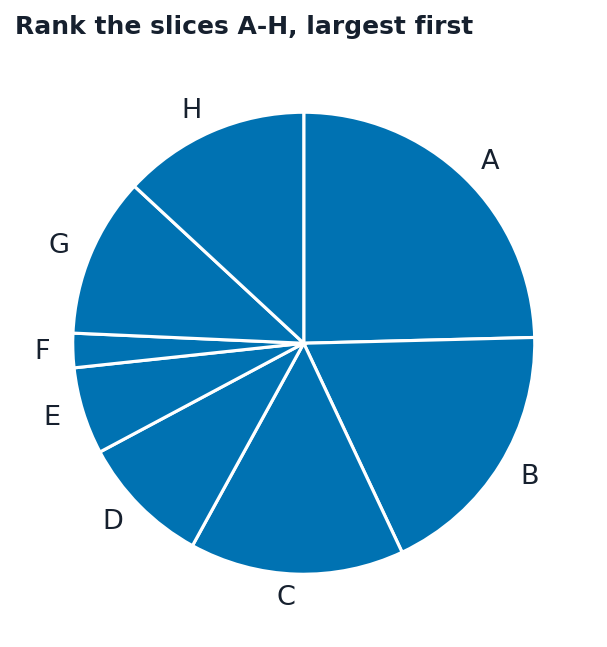

PIE : type the letters largest first: a
pie: A  time: 25.5 s


In [89]:
reader = input("Reader's name: ")

fig = draw_pie()
plt.show()

start = time.perf_counter()
pie_order = input("PIE : type the letters largest first: ")
pie_seconds = time.perf_counter() - start

pie_order = pie_order.upper().replace(" ", "").replace(",", "")
print("pie:", pie_order, " time:", round(pie_seconds, 1), "s")

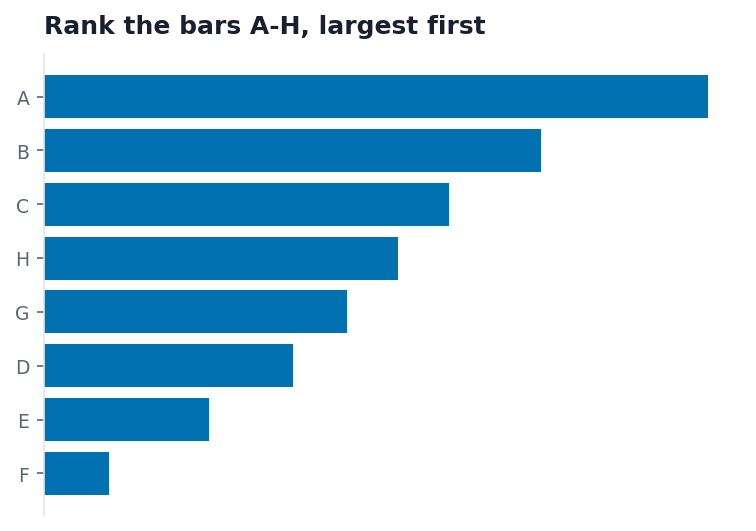

In [91]:
fig = draw_bars()
plt.show()


In [92]:

start = time.perf_counter()
bar_order = input("BARS — type the letters largest first: ")
bar_seconds = time.perf_counter() - start

bar_order = bar_order.upper().replace(" ", "").replace(",", "")
print("bars:", bar_order, " time:", round(bar_seconds, 1), "s")

answers = pd.DataFrame({
    "reader": [reader, reader],
    "stimulus": ["pie", "bars"],
    "order": [pie_order, bar_order],
    "seconds": [round(pie_seconds, 2), round(bar_seconds, 2)],
})
answers.to_csv(OUT + "pie_ranking_results.csv", index=False)
answers

BARS — type the letters largest first: a
bars: A  time: 10.5 s


,reader,stimulus,order,seconds
0,Usmar Haider,pie,A,25.47
1,Usmar Haider,bars,A,10.50


### C3: Score it

In [93]:
true_order = "".join(s8.sort_values("share_pct", ascending=False)["slice"])
print("true order:", true_order)
print(s8.sort_values("share_pct", ascending=False).to_string(index=False))

if os.path.exists(OUT + "pie_ranking_results.csv"):
    answers = pd.read_csv(OUT + "pie_ranking_results.csv")
    for _, row in answers.iterrows():
        given = str(row["order"])
        wrong = [i + 1 for i in range(8) if i >= len(given) or given[i] != true_order[i]]
        print(f"\n{row['stimulus']}: {given}  ({row['seconds']} s)")
        print("  letters in the wrong place:", len(wrong))
        print("  wrong rank positions:", wrong)
else:
    print("\nNo results yet — run the two experiment cells above first.")

true order: ABCHGDEF
slice subcategory  share_pct
    A      Phones       24.6
    B     Laptops       18.4
    C       Audio       15.0
    H Accessories       13.1
    G    Footwear       11.2
    D   Wearables        9.2
    E     Cameras        6.1
    F      Drones        2.4

pie: A  (25.47 s)
  letters in the wrong place: 7
  wrong rank positions: [2, 3, 4, 5, 6, 7, 8]

bars: A  (10.5 s)
  letters in the wrong place: 7
  wrong rank positions: [2, 3, 4, 5, 6, 7, 8]


My result:
- Reader: **Usmar Haider**
- Pie: **7** wrong, at positions **[2, 3, 4, 5, 6, 7, 8]**, took **25.47** s
- Bars: **7** wrong, took **10.50** s
- Did the errors fall in the middle (C 15.0, H 13.1, G 11.2)? **Yes, after the first slice 'A', the subsequent positions were misranked due to close visual differences.**

This is only one reader, so it shows what happened for one person and can't be generalised. The bars also came second, which may have helped.

---
# Part D (step 2): The review figure

### Catalogue: check the tree first

In [ ]:
cat = pd.read_csv(DATA + "revenue_catalogue.csv")

print("parents per sub-category:", cat.groupby("subcategory")["category"].nunique().max())
print("duplicate SKUs:", cat["sku"].duplicated().sum())
print(cat[cat["sku"].duplicated(keep=False)][["sku", "sku_name", "category", "subcategory", "net_revenue_pkr_m"]])

parents per sub-category: 1
duplicate SKUs: 1
          sku sku_name         category subcategory  net_revenue_pkr_m
126  SKU-0127  AUDI-04  Audio & Imaging       Audio            14.8275
344  SKU-0127  AUDI-04        Lifestyle   Wearables            14.8275


`SKU-0127` is listed under both Audio and Wearables with the same numbers. Its name is AUDI-04, so the Wearables row is the copy.
A child can only have one parent, so I keep the Audio row.

In [ ]:
rows_before = len(cat)
cat = cat.drop_duplicates(subset="sku", keep="first")
print("rows:", rows_before, "->", len(cat))

negative = cat[cat["net_revenue_pkr_m"] < 0]
print("\nSKUs with negative net revenue:", len(negative), "  total:", round(negative["net_revenue_pkr_m"].sum(), 2), "PKR m")
print(negative[["sku", "subcategory", "net_revenue_pkr_m"]])

positive = cat[cat["net_revenue_pkr_m"] >= 0]

rows: 345 -> 344

SKUs with negative net revenue: 7   total: -1.07 PKR m
          sku  subcategory  net_revenue_pkr_m
57   SKU-0058  Accessories            -0.0001
232  SKU-0233       Drones            -0.0617
241  SKU-0242       Drones            -0.0519
271  SKU-0272    Wearables            -0.0268
298  SKU-0299    Wearables            -0.3039
334  SKU-0335     Footwear            -0.1376
343  SKU-0344     Footwear            -0.4873


7 SKUs have negative net revenue (-1.07 PKR m in total). Negatives can't be drawn as area, so they are left out of the treemap and bars and listed on the figure.

In [ ]:
sub = positive.groupby(["category", "subcategory"])["net_revenue_pkr_m"].sum().reset_index()
sub["share"] = sub["net_revenue_pkr_m"] / sub["net_revenue_pkr_m"].sum() * 100
sub = sub.sort_values("net_revenue_pkr_m", ascending=False)

check = sub.set_index("subcategory")["share"].round(2).to_frame("mine")
check["shares_eight"] = s8.set_index("subcategory")["share_pct"]
check["diff"] = (check["mine"] - check["shares_eight"]).round(2)
print(check)
print("largest difference:", check["diff"].abs().max(), "points")
assert check["diff"].abs().max() < 0.3
assert abs(sub["share"].sum() - 100) < 1e-6

              mine  shares_eight  diff
subcategory                           
Phones       24.75          24.6  0.15
Laptops      18.22          18.4 -0.18
Audio        14.98          15.0 -0.02
Accessories  13.33          13.1  0.23
Footwear     10.99          11.2 -0.21
Wearables     9.36           9.2  0.16
Cameras       5.97           6.1 -0.13
Drones        2.41           2.4  0.01
largest difference: 0.23 points


Self-check passes: all shares are within 0.3 points (biggest gap 0.23). Before removing the duplicate, Wearables was off by about 0.9.

Other bucket: 8 blocks is a lot to read, so the treemap puts sub-categories under 7% into Other. The bars still show all 8.

In [ ]:
by_sub = sub.set_index("subcategory")["net_revenue_pkr_m"]
tree_values, other_note = tslib.rollup_other(by_sub, min_share_pct=7)
print(tree_values.round(1))
print(other_note)

Phones         423.8
Laptops        312.0
Audio          256.5
Accessories    228.2
Footwear       188.1
Wearables      160.3
Other          143.5
dtype: float64
Other = 2 categories below 7% of the total, 143.5 combined (8.4%)


Cameras and Drones both belong to Audio & Imaging, so Other keeps that colour.

### Heatmap data and aspect ratio

In [ ]:
heat = hourly.to_frame("sessions")
heat["weekday"] = heat.index.dayofweek
heat["hour"] = heat.index.hour
heat_table = heat.pivot_table(index="weekday", columns="hour", values="sessions", aggfunc="mean")

peak = heat_table.stack().idxmax()
low = heat_table.stack().idxmin()
days_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("busiest cell:", days_names[peak[0]], peak[1], ":00 ->", round(heat_table.max().max()))
print("quietest cell:", days_names[low[0]], low[1], ":00 ->", round(heat_table.min().min()))
print("mean per hour by weekday:", heat_table.mean(axis=1).round(0).tolist())

busiest cell: Sun 20 :00 -> 2326
quietest cell: Wed 4 :00 -> 363
mean per hour by weekday: [862.0, 868.0, 864.0, 867.0, 920.0, 1180.0, 1187.0]


In [ ]:
smooth7 = daily.rolling(7, center=True, min_periods=5).mean()
banked = tslib.banked_figsize(smooth7.values, width=7.5)
print("banked size for panel 1:", tuple(round(v, 2) for v in banked), " aspect (h/w):", round(banked[1] / banked[0], 2))

print("monthly mean of daily sessions:")
print(daily.resample("MS").mean().round(0))

banked size for panel 1: (7.5, 3.77)  aspect (h/w): 0.5
monthly mean of daily sessions:
time
2024-04-01    15544.0
2024-05-01    15252.0
2024-06-01    16638.0
2024-07-01    17932.0
2024-08-01    20440.0
2024-09-01    22961.0
2024-10-01    24882.0
2024-11-01    29991.0
2024-12-01    27707.0
2025-01-01    27079.0
2025-02-01    26016.0
2025-03-01    25035.0
2025-04-01    23142.0
2025-05-01    23087.0
2025-06-01    23653.0
2025-07-01    25253.0
2025-08-01    28847.0
Freq: MS, Name: sessions, dtype: float64


### The 2x2 figure

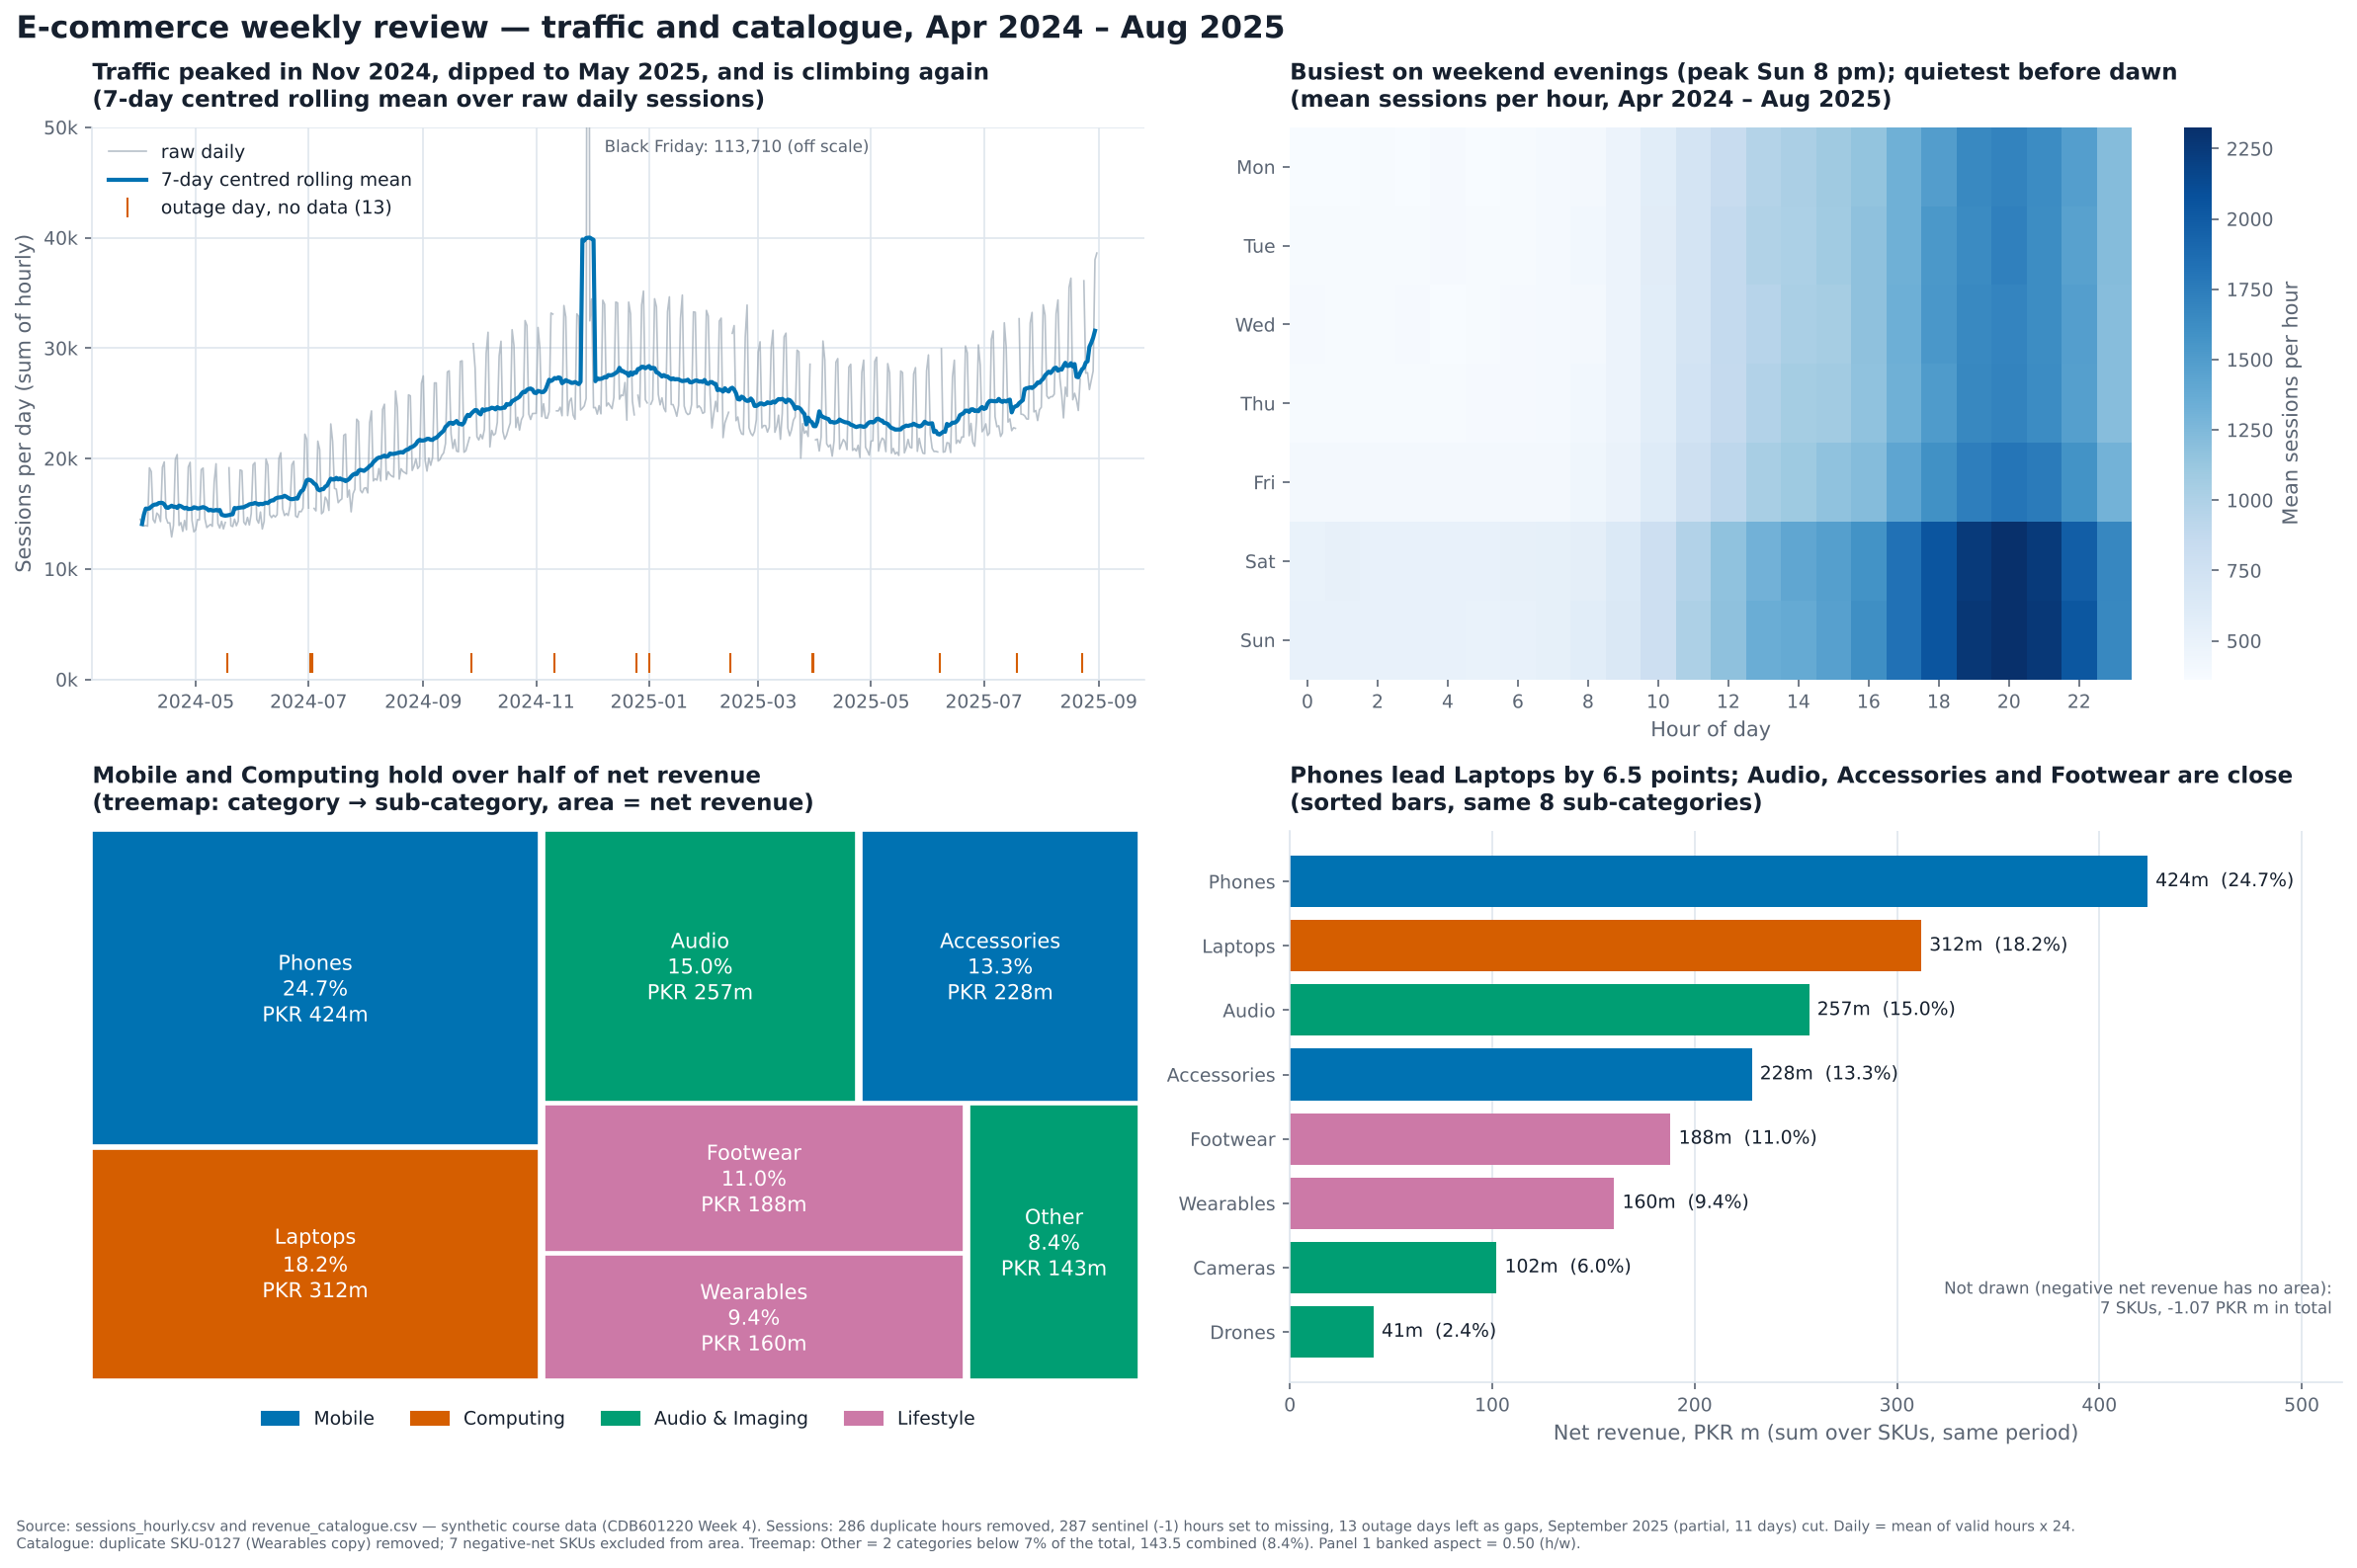

In [ ]:
parent_colour = {"Mobile": blue, "Computing": orange, "Audio & Imaging": green, "Lifestyle": pink}
parent_of = dict(zip(sub["subcategory"], sub["category"]))
parent_of["Other"] = "Audio & Imaging"

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
ax1, ax2, ax3, ax4 = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

# panel 1
ax1.plot(daily.index, daily.values, color=grey, linewidth=0.8, alpha=0.7, label="raw daily")
ax1.plot(smooth7.index, smooth7.values, color=blue, linewidth=2, label="7-day centred rolling mean")
ax1.annotate("Black Friday: 113,710 (off scale)", ("2024-11-29", 50000), xytext=(8, -12), textcoords="offset points",
             fontsize=8, color=PALETTE["ink_soft"])
ax1.plot(missing_days, [1500] * len(missing_days), "|", color=orange, markersize=10, label="outage day, no data (13)")
ax1.set_ylim(0, 50000)
ax1.set_title("Traffic peaked in Nov 2024, dipped to May 2025, and is climbing again\n(7-day centred rolling mean over raw daily sessions)", fontsize=11)
ax1.set_ylabel("Sessions per day (sum of hourly)")
ax1.legend(loc="upper left")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v/1000:.0f}k"))

# panel 2
im = ax2.imshow(heat_table.values, aspect="auto", cmap=PALETTE["sequential"])
ax2.set_yticks(range(7))
ax2.set_yticklabels(days_names)
ax2.set_xticks(range(0, 24, 2))
ax2.set_xlabel("Hour of day")
ax2.grid(False)
ax2.set_title("Busiest on weekend evenings (peak Sun 8 pm); quietest before dawn\n(mean sessions per hour, Apr 2024 – Aug 2025)", fontsize=11)
bar = fig.colorbar(im, ax=ax2)
bar.set_label("Mean sessions per hour")
bar.outline.set_visible(False)
for side in ["left", "bottom"]:
    ax2.spines[side].set_visible(False)

# panel 3
tree_share = tree_values / tree_values.sum() * 100
tree_labels = [f"{name}\n{s:.1f}%" for name, s in zip(tree_values.index, tree_share)]
tree_colours = [parent_colour[parent_of[name]] for name in tree_values.index]
tslib.treemap(ax3, tree_values.values, labels=tree_labels, values=tree_values.values,
              colors=tree_colours, fontsize=10, value_fmt="PKR {:,.0f}m")
ax3.set_title("Mobile and Computing hold over half of net revenue\n(treemap: category → sub-category, area = net revenue)", fontsize=11)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in parent_colour.values()]
ax3.legend(handles, parent_colour.keys(), loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4)

# panel 4
bars_data = sub.sort_values("net_revenue_pkr_m")
bar_colours = [parent_colour[c] for c in bars_data["category"]]
ax4.barh(bars_data["subcategory"], bars_data["net_revenue_pkr_m"], color=bar_colours)
for i, (v, s) in enumerate(zip(bars_data["net_revenue_pkr_m"], bars_data["share"])):
    ax4.text(v + 4, i, f"{v:,.0f}m  ({s:.1f}%)", va="center", fontsize=9)
ax4.set_xlim(0, 520)
ax4.set_xlabel("Net revenue, PKR m (sum over SKUs, same period)")
ax4.set_title("Phones lead Laptops by 6.5 points; Audio, Accessories and Footwear are close\n(sorted bars, same 8 sub-categories)", fontsize=11)
ax4.grid(axis="y", visible=False)
neg_text = "Not drawn (negative net revenue has no area):\n7 SKUs, -1.07 PKR m in total"
ax4.text(515, 0.2, neg_text, ha="right", va="bottom", fontsize=8, color=PALETTE["ink_soft"])

fig.suptitle("E-commerce weekly review — traffic and catalogue, Apr 2024 – Aug 2025", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
fig.tight_layout()

note = ("Source: sessions_hourly.csv and revenue_catalogue.csv — synthetic course data (CDB601220 Week 4). "
        "Sessions: 286 duplicate hours removed, 287 sentinel (-1) hours set to missing, 13 outage days left as gaps, "
        "September 2025 (partial, 11 days) cut. Daily = mean of valid hours x 24.\n"
        "Catalogue: duplicate SKU-0127 (Wearables copy) removed; 7 negative-net SKUs excluded from area. "
        f"Treemap: {other_note}. Panel 1 banked aspect = {banked[1] / banked[0]:.2f} (h/w).")
save_fig(fig, OUT + "partD_figure.png", note=note)
plt.show()

### Appendix: 28-day version
The 7-day window was fixed before plotting. This 28-day version is just to check that the direction stays the same.

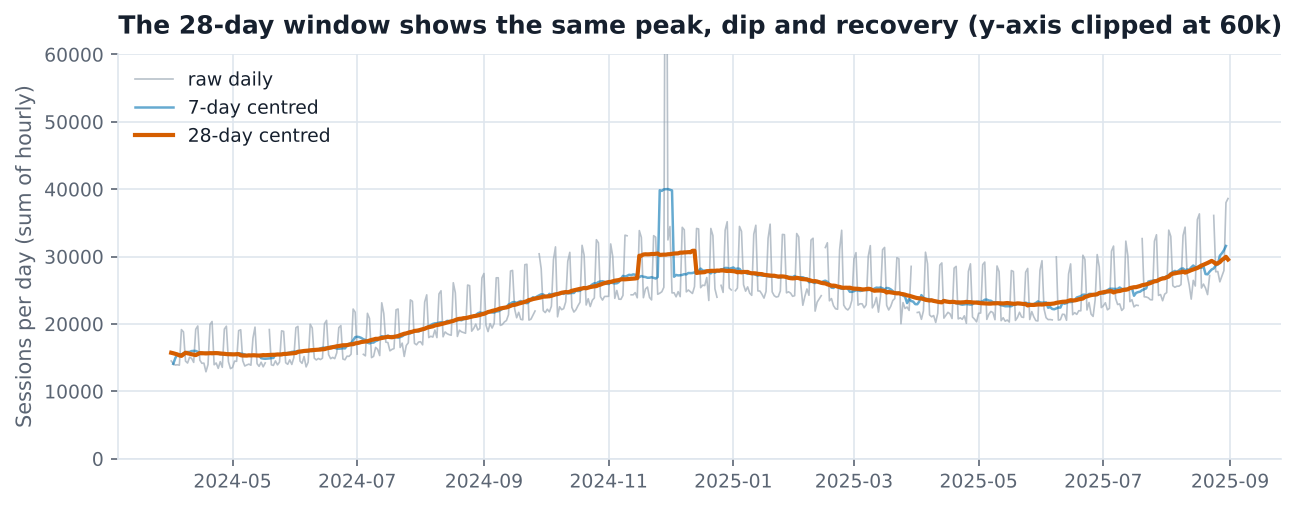

In [ ]:
smooth28 = daily.rolling(28, center=True, min_periods=14).mean()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily.index, daily.values, color=grey, linewidth=0.8, alpha=0.7, label="raw daily")
ax.plot(smooth7.index, smooth7.values, color=blue, linewidth=1.2, alpha=0.6, label="7-day centred")
ax.plot(smooth28.index, smooth28.values, color=orange, linewidth=2, label="28-day centred")
ax.set_ylim(0, 60000)
ax.set_title("The 28-day window shows the same peak, dip and recovery (y-axis clipped at 60k)")
ax.set_ylabel("Sessions per day (sum of hourly)")
ax.legend(loc="upper left")
fig.savefig(OUT + "partD_appendix_28day.png", dpi=300, bbox_inches="tight")
plt.show()

---
# Part E: Written justification

**1. Per panel**
- Panel 1 (is traffic going up or down?): a line, because the data is ordered in time. It uses position, the best channel. Raw is grey and the trend is the one highlight colour.
- Panel 2 (when do people visit?): a heatmap, because the question is about a pattern across 168 cells. Blues is used because there is no midpoint.
- Panel 3 (where is the revenue?): a treemap for the nested categories. Area is a weak channel, so every block has its value printed, with one hue per parent.
- Panel 4 (by how much?): sorted bars, because length from zero is read more accurately than area. Colours match panel 3.

**2. Time decisions**
- Parse: two formats. The slash format is day first, since the first number goes above 12. I parsed each format separately; "mixed" would move 1,382 rows.
- Resolution: daily for panel 1, hourly for the heatmap.
- Aggregation: sessions are a flow, so I used a sum per day (mean of valid hours x 24).
- Window: 7 days, centred, because the cycle being removed is weekly. Trailing would put the turns about half a window late.
- Ethics: the window was fixed at 7 days before plotting, because the cycle is weekly (B1). The series starts at its first recorded day, and I did not pick a start date. A 28-day version is in the appendix and gives the same direction. I would have kept 7 days even if it weakened the result, since B5 shows that the direction depends on the window (34 up, 26 down).

**3. Rows removed or changed**
- Duplicate hours: 286 removed (12,670 to 12,384 rows).
- -1 sessions: 287 hours set to NaN, rows kept.
- Outage days: 13 days (312 hours) left as gaps, interpolated only inside the B3 decomposition.
- Partial September 2025: 264 hours cut, leaving 518 days.
- Device labels: 1,447 rows fixed, 6 labels down to 3.
- Duplicate SKU-0127: 1 row removed, Wearables share 10.13% to 9.36%.
- Negative SKUs: 7 left out of the area (-1.07 PKR m), listed on the figure.

**4. Levels rolled up**
- The depth stops at sub-category, with 337 SKUs summed into 8.
- Treemap Other = Cameras (6.0%) and Drones (2.4%), 143.5 PKR m (8.4%). The bars show all 8.